# Indian Startup Funding Analytics — Stage 2: Exploratory Data Analysis

**Source file:** `startup_funding.csv` (3,044 rows × 10 columns, 2 Jan 2015 – 13 Jan 2020)
**Purpose:** understand the raw data *before* the final cleaning pipeline (Stage 3) is written.

### Metric definitions used throughout
| Term | Meaning |
|---|---|
| **Funding record** | One row in the file. It is *not* a verified funding round — the same round can be listed more than once, and one startup can appear many times. |
| **Disclosed amount** | A row whose `Amount in USD` is a real number. Rows with N/A / undisclosed / unknown are *missing*, never zero. |
| **Unique startups** | Distinct startup names after light, documented normalization (see section 2). It is an estimate, not a verified company count. |
| **Investor appearances** | How many records an investor name appears on after splitting multi-investor cells. It is *not* a count of verified investments and says nothing about investor performance. |

### Ground rules
* The raw CSV is **never modified**. Section 2 builds an *EDA working view* in memory with small, documented, reversible normalizations so that groupings are meaningful. The final, fully documented cleaning pipeline is Stage 3.
* Every number in this notebook is computed from the file. Figures are also saved to `../reports/figures/`.
* Amounts are used exactly as given (the column is labelled USD). No currency or unit conversion is applied.

In [1]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 55)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# --- locate the data (works when run from notebooks/ or from the project root) ---
CANDIDATES = [Path("../data/startup_funding.csv"), Path("data/startup_funding.csv"), Path("startup_funding.csv")]
DATA = next((p for p in CANDIDATES if p.exists()), None)
assert DATA is not None, "startup_funding.csv not found - place it in ../data/"
FIG_DIR = Path("../reports/figures") if Path("../reports").exists() else Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

PAL = {"main": "#1F4E79", "accent": "#E07B39", "grey": "#8A8F98", "light": "#BFD3E6"}
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.25, "axes.axisbelow": True,
})

def usd(v, d=1):
    # Compact USD label: $1.2B / $34.5M / $12K
    if pd.isna(v): return "n/a"
    a = abs(v)
    for div, suf in [(1e9, "B"), (1e6, "M"), (1e3, "K")]:
        if a >= div: return f"${v/div:,.{d}f}{suf}"
    return f"${v:,.0f}"

def pct(x, d=1): return f"{x*100:.{d}f}%"

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

def barh(ax, s, title, xlabel="", money=False, color=None):
    s = s.sort_values()
    ax.barh(s.index.astype(str), s.values, color=color or PAL["main"])
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel)
    if money: ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: usd(v, 0)))
    for i, v in enumerate(s.values):
        ax.text(v, i, "  " + (usd(v) if money else f"{v:,.0f}"), va="center", fontsize=8)
    ax.grid(axis="y", visible=False); ax.margins(x=0.18)

print("Setup complete. Data file:", DATA)

Setup complete. Data file: ../data/startup_funding.csv


## 1. Load the raw data and audit it (Phase 1 recap)

Everything is read as **text** (`dtype=str`, `keep_default_na=False`) so that pandas does not silently convert `N/A`, `nan` or other placeholders and nothing is hidden.

In [2]:
EXPECTED_COLUMNS = ['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical', 'SubVertical',
                    'City  Location', 'Investors Name', 'InvestmentnType', 'Amount in USD', 'Remarks']
raw = pd.read_csv(DATA, dtype=str, keep_default_na=False, encoding="utf-8-sig")
assert list(raw.columns) == EXPECTED_COLUMNS, f"Unexpected columns: {list(raw.columns)}"
print(f"Rows x columns : {raw.shape[0]:,} x {raw.shape[1]}")
print("Exact column names (note the DOUBLE space in 'City  Location'):")
for c in raw.columns: print("   ", repr(c))

Rows x columns : 3,044 x 10
Exact column names (note the DOUBLE space in 'City  Location'):
    'Sr No'
    'Date dd/mm/yyyy'
    'Startup Name'
    'Industry Vertical'
    'SubVertical'
    'City  Location'
    'Investors Name'
    'InvestmentnType'
    'Amount in USD'
    'Remarks'


In [3]:
print("FIRST 10 ROWS")
display(raw.head(10))
print("LAST 10 ROWS")
display(raw.tail(10))

FIRST 10 ROWS


,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",
5,6,13/01/2020,Pando,Logistics,"Open-market, freight management platform",Chennai,Chiratae Ventures,Series A,"90,00,000",
6,7,10/01/2020,Zomato,Hospitality,Online Food Delivery Platform,Gurgaon,Ant Financial,Private Equity Round,"15,00,00,000",
7,8,12/12/2019,Ecozen,Technology,Agritech,Pune,Sathguru Catalyzer Advisors,Series A,"60,00,000",
8,9,06/12/2019,CarDekho,E-Commerce,Automobile,Gurgaon,Ping An Global Voyager Fund,Series D,"7,00,00,000",
9,10,03/12/2019,Dhruva Space,Aerospace,Satellite Communication,Bengaluru,"Mumbai Angels, Ravikanth Reddy",Seed,"5,00,00,000",


LAST 10 ROWS


,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
3034,3035,24/01/2015,Aasaanjobs,nan,nan,nan,"Inventus Capital Partners, IDG Ventures",Seed Funding,"15,00,000",
3035,3036,24/01/2015,Impartus,nan,nan,nan,Kaizen Private Equity,Private Equity,N/A,Series A
3036,3037,25/01/2015,Thrill App,nan,nan,nan,People Group (Shaadi.com),Private Equity,"10,00,000",Strategic Funding
3037,3038,27/01/2015,CarDekho.com,nan,nan,nan,"Hillhouse Capital, Tybourne Capital",Private Equity,"5,00,00,000",Series B
3038,3039,28/01/2015,Grabhouse.com,nan,nan,nan,"Kalaari Capital, Sequoia Capital",Private Equity,"25,00,000",Series A
3039,3040,29/01/2015,Printvenue,nan,nan,nan,Asia Pacific Internet Group,Private Equity,"45,00,000",
3040,3041,29/01/2015,Graphene,nan,nan,nan,KARSEMVEN Fund,Private Equity,"8,25,000",Govt backed VC Fund
3041,3042,30/01/2015,Mad Street Den,nan,nan,nan,"Exfinity Fund, GrowX Ventures.",Private Equity,"15,00,000",
3042,3043,30/01/2015,Simplotel,nan,nan,nan,MakeMyTrip,Private Equity,N/A,"Strategic Funding, Minority stake"
3043,3044,31/01/2015,couponmachine.in,nan,nan,nan,UK based Group of Angel Investors,Seed Funding,"1,40,000",


In [4]:
# Types and memory as pandas would infer them with default settings
typed = pd.read_csv(DATA, encoding="utf-8-sig")
info = pd.DataFrame({
    "pandas_dtype": typed.dtypes.astype(str),
    "non_null (default NA rules)": typed.notna().sum(),
    "unique": typed.nunique(),
    "memory_KB": (typed.memory_usage(deep=True, index=False) / 1024).round(1),
})
display(info)
print(f"Total memory: {typed.memory_usage(deep=True).sum()/1024**2:.2f} MB")
print("\nOnly 'Sr No' is numeric. The date and the amount load as text and need explicit conversion.")

,pandas_dtype,non_null (default NA rules),unique,memory_KB
Sr No,int64,3044,3044,23.80
Date dd/mm/yyyy,str,3044,1035,175.40
Startup Name,str,3044,2459,173.50
Industry Vertical,str,2873,821,191.60
SubVertical,str,2108,1942,192.40
City Location,str,2864,112,164.40
Investors Name,str,3020,2412,245.50
InvestmentnType,str,3040,55,184.60
Amount in USD,str,2084,471,148.30
Remarks,str,419,72,106.80


Total memory: 1.57 MB

Only 'Sr No' is numeric. The date and the amount load as text and need explicit conversion.


In [5]:
# ---- text helper: removes the literal escape artifacts found in this file ----
# The CSV contains visible text such as  \xc2\xa0  (an escaped non-breaking space) and  \n  inside values.
def clean_text(x):
    if pd.isna(x): return ""
    s = str(x)
    s = re.sub(r"\\+xe2\\+x80\\+x93", "-", s)      # escaped en dash
    s = re.sub(r"\\+x[0-9a-fA-F]{2}", "", s)        # escaped bytes such as \xc2\xa0
    s = re.sub(r"\\+n", " ", s)                      # literal \n
    return re.sub(r"\s+", " ", s).strip()

PLACEHOLDERS = {"", "nan", "n/a", "na", "null", "none", "-", "--", "undisclosed", "unknown"}

rows = []
for c in raw.columns:
    cleaned = raw[c].map(clean_text)
    low = cleaned.str.lower()
    n_empty = int((raw[c].str.strip() == "").sum())
    n_ph = int(low.isin(PLACEHOLDERS - {""}).sum())
    rows.append({"column": c, "empty_cells": n_empty, "placeholder_text": n_ph,
                 "missing_total": n_empty + n_ph, "missing_%": (n_empty + n_ph) / len(raw) * 100})
missing = pd.DataFrame(rows).set_index("column")
display(missing)

print("Placeholder strings actually present (after removing escape artifacts):")
for c in raw.columns:
    vc = raw[c].map(clean_text)
    vc = vc[vc.str.lower().isin(PLACEHOLDERS - {""})].value_counts()
    if len(vc): print(f"  {c!r:22}", {k: int(v) for k, v in vc.items()})

,empty_cells,placeholder_text,missing_total,missing_%
column,,,,
Sr No,0,0,0,0.00
Date dd/mm/yyyy,0,0,0,0.00
Startup Name,0,0,0,0.00
Industry Vertical,0,171,171,5.62
SubVertical,0,936,936,30.75
City Location,6,174,180,5.91
Investors Name,3,32,35,1.15
InvestmentnType,3,1,4,0.13
Amount in USD,0,971,971,31.90


Placeholder strings actually present (after removing escape artifacts):
  'Industry Vertical'    {'nan': 171}
  'SubVertical'          {'nan': 936}
  'City  Location'       {'nan': 171, 'N/A': 3}
  'Investors Name'       {'N/A': 21, 'Undisclosed': 11}
  'InvestmentnType'      {'nan': 1}
  'Amount in USD'        {'N/A': 963, 'undisclosed': 3, 'Undisclosed': 3, 'unknown': 1, 'nan': 1}
  'Remarks'              {'nan': 2064, 'N/A': 13}


In [6]:
# ---- duplicates ----
clean_all = raw.drop(columns="Sr No").apply(lambda s: s.map(clean_text))
print("Exact duplicate rows (all columns)              :", int(raw.duplicated().sum()))
print("Duplicates ignoring Sr No (after text cleaning) :", int(clean_all.duplicated().sum()))
biz_key = ["Date dd/mm/yyyy", "Startup Name", "Investors Name", "Amount in USD"]
print("Same date + startup + investors + amount        :", int(clean_all.duplicated(biz_key).sum()))
print("Same date + startup (any other values)          :", int(clean_all.duplicated(["Date dd/mm/yyyy", "Startup Name"], keep=False).sum()), "rows")
sr = raw["Sr No"].astype(int)
print("\nSr No: unique =", sr.nunique(), "| min =", sr.min(), "| max =", sr.max(), "| gaps =", int((sr.diff().dropna() != 1).sum()))

Exact duplicate rows (all columns)              : 0
Duplicates ignoring Sr No (after text cleaning) : 0
Same date + startup + investors + amount        : 0
Same date + startup (any other values)          : 0 rows

Sr No: unique = 3044 | min = 1 | max = 3044 | gaps = 0


## 2. EDA working view (light, documented normalization)

Goal: make groupings meaningful **without** changing the raw data. Rules applied here (final versions are decided in Stage 3):

| Field | Rule | Evidence required before merging |
|---|---|---|
| Text | Remove escape artifacts (`\xc2\xa0`, `\n`), collapse spaces | Artifacts are not real characters |
| Amount | Remove commas (Indian *and* Western grouping give the same integer), drop a trailing `+`; `N/A`/undisclosed/unknown → **missing** (never 0) | None needed — pure formatting |
| Date | Parse as **day/month/year** with an explicit format; repair only obviously malformed separators; flag every repaired/invalid row | No second part exceeds 12 anywhere, so day-first is supported |
| City | Only official renames, obvious typos, and well-known localities of a city; multi-city cells become `Multiple locations` | `Bangalore`=`Bengaluru`, `Gurgaon`=`Gurugram`; **Delhi and New Delhi are kept separate** |
| Industry | Case/spelling variants of the *same* label only (e.g. eCommerce / E-Commerce / ECommerce); labels used < 5 times become `Other / long-tail` | Same label after case & punctuation removal |
| Investment type | Spelling variants only (e.g. `Seed/ Angel Funding`, `Seed / Angle Funding`) | Same words after normalization |
| Startup | Match ignoring case, spaces, punctuation and a trailing `.com/.in/.co`; `Ola` and `Ola Cabs` are **not** merged | Identical normalized key |
| Investors | Split on `,` `;` ` & ` ` and ` `/`; trim; ignore placeholders (Others, Undisclosed); a few major firms aliased | Documented alias list |

In [7]:
# ---------- AMOUNT ----------
def parse_amount(x):
    s0 = "" if pd.isna(x) else str(x)
    s = clean_text(s0)
    if s.lower() in PLACEHOLDERS: return np.nan, "missing"
    t = s.rstrip("+").replace(",", "").strip()
    try: v = float(t)
    except ValueError: return np.nan, "unparseable"
    strict = re.fullmatch(r"\d[\d,]*(\.\d+)?", s0) is not None
    return v, ("disclosed" if strict else "repaired")

# ---------- DATE ----------
def parse_date(x):
    s0 = "" if pd.isna(x) else str(x)
    s = clean_text(s0)
    d = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    if pd.notna(d) and s == s0: return d, "valid"
    t = s.replace("//", "/").replace(".", "/")
    t = re.sub(r"^(\d{1,2})/(\d{2})(\d{4})$", r"\1/\2/\3", t)      # 05/072018 -> 05/07/2018
    t = re.sub(r"/(\d{3})$", lambda m: "/2" + m.group(1), t)       # 01/07/015 -> 01/07/2015
    d = pd.to_datetime(t, format="%d/%m/%Y", errors="coerce")
    return d, ("repaired" if pd.notna(d) else "invalid")

# ---------- STARTUP ----------
def startup_key(s):
    k = s.lower()
    k = re.sub(r"^https?://(www\.)?", "", k); k = re.sub(r"/.*$", "", k)
    k = re.sub(r"\.(com|in|co|org|net|io)(\.in)?$", "", k)
    return re.sub(r"[^a-z0-9]", "", k) or s.lower()

# ---------- INDUSTRY ----------
IND_CANON = {
    "ecommerce": "eCommerce", "ecommece": "eCommerce",
    "fintech": "FinTech", "financialtech": "FinTech",
    "edtech": "EdTech", "healthcare": "Healthcare",
    "foodbeverage": "Food & Beverage", "foodandbeverage": "Food & Beverage",
    "foodbeverages": "Food & Beverage", "foodandbeverages": "Food & Beverage",
    "transportation": "Transportation", "transport": "Transportation",
    "informationtechnology": "Information Technology", "it": "Information Technology",
    "consumerinternet": "Consumer Internet", "consumerinterne": "Consumer Internet",
    "saas": "SaaS",
}
def key_text(s): return re.sub(r"[^a-z0-9]", "", s.lower())

# ---------- CITY ----------
CITY_MAP = {"bangalore": "Bengaluru", "gurgaon": "Gurugram", "ahemadabad": "Ahmedabad", "ahemdabad": "Ahmedabad",
            "kolkatta": "Kolkata", "nw delhi": "New Delhi", "bhubneswar": "Bhubaneswar",
            "kormangala": "Bengaluru", "andheri": "Mumbai", "chembur": "Mumbai", "taramani": "Chennai"}
REGION_ONLY = {"us", "usa", "india", "california", "karnataka", "haryana", "uttar pradesh", "kerala", "missourie"}
def std_city(x):
    s = clean_text(x).rstrip(", ").strip()
    if s.lower() in PLACEHOLDERS: return np.nan
    if re.search(r"[/&,]| and ", s): return "Multiple locations"
    if s.lower() in REGION_ONLY: return "Region/country only"
    return CITY_MAP.get(s.lower(), s)

# ---------- INVESTMENT TYPE ----------
def std_invtype(x):
    s = clean_text(x)
    if s.lower() in PLACEHOLDERS: return np.nan
    k = re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", s.lower())).strip()
    if re.search(r"seed.*(angel|angle)|(angel|angle).*seed", k): return "Seed / Angel Funding"
    if re.fullmatch(r"seed( funding)?( round)?", k): return "Seed Funding"
    if re.fullmatch(r"angel( funding| round)?", k): return "Angel Funding"
    if re.fullmatch(r"private ?equity( round)?", k): return "Private Equity"
    if re.fullmatch(r"pre ?series a", k): return "Pre-Series A"
    m = re.fullmatch(r"series ([a-j])( extension)?", k)
    if m: return f"Series {m.group(1).upper()}"
    if re.fullmatch(r"debt( funding)?|structured debt|term loan", k): return "Debt Funding"
    if re.fullmatch(r"crowd funding", k): return "Crowd Funding"
    return "Other / rare"

# ---------- STAGE HIDDEN IN REMARKS ----------
STAGE_RE = re.compile(r"\b(pre[- ]?series a|series [a-j])\b", re.I)
def stage_from_remarks(x):
    m = STAGE_RE.search(clean_text(x))
    if not m: return np.nan
    g = re.sub(r"[- ]+", " ", m.group(1).lower())
    return "Pre-Series A" if g.startswith("pre") else "Series " + g.split()[-1].upper()

# ---------- INVESTORS ----------
INV_PLACEHOLDERS = {"others", "other", "undisclosed", "undisclosed investors", "undisclosed investor",
                    "n/a", "nan", "unknown", ""}
INV_ALIASES = [(re.compile(r"^sequoia\b"), "Sequoia Capital (all variants)"),
               (re.compile(r"^accel\b"), "Accel (all variants)"),
               (re.compile(r"^saif partners"), "SAIF Partners")]
def split_investors(x):
    s = clean_text(x)
    if s.lower() in PLACEHOLDERS: return []
    out, seen = [], set()
    for p in re.split(r",|;|\s&\s|\sand\s|/", s):
        p = re.sub(r"\s+", " ", p).strip().rstrip(".").strip()
        k = p.lower()
        if k in INV_PLACEHOLDERS or len(k) < 2 or k in seen: continue
        seen.add(k); out.append(p)
    return out
def inv_label(p):
    for rx, lab in INV_ALIASES:
        if rx.match(p.lower()): return lab
    return p

print("Normalization rules defined.")

Normalization rules defined.


In [8]:
# ---------- BUILD THE EDA WORKING VIEW ----------
am = raw["Amount in USD"].map(parse_amount)
dt = raw["Date dd/mm/yyyy"].map(parse_date)

df = pd.DataFrame({
    "record_id":      raw["Sr No"].astype(int),
    "date":           pd.to_datetime(dt.map(lambda t: t[0])),
    "date_status":    dt.map(lambda t: t[1]),
    "startup_clean":  raw["Startup Name"].map(clean_text),
    "industry_clean": raw["Industry Vertical"].map(clean_text),
    "subvertical":    raw["SubVertical"].map(clean_text),
    "city_eda":       raw["City  Location"].map(std_city),
    "investors_raw":  raw["Investors Name"].map(clean_text),
    "invtype_eda":    raw["InvestmentnType"].map(std_invtype),
    "amount_usd":     am.map(lambda t: t[0]).astype(float),
    "amount_status":  am.map(lambda t: t[1]),
    "remarks":        raw["Remarks"].map(clean_text),
})
df["stage_from_remarks"] = raw["Remarks"].map(stage_from_remarks)

# startup: key + most common spelling per key
df["startup_key"] = df["startup_clean"].map(startup_key)
disp = df.groupby("startup_key")["startup_clean"].agg(lambda x: x.value_counts().index[0])
df["startup_eda"] = df["startup_key"].map(disp)

# industry: standardize variants, group the long tail
ind_key = df["industry_clean"].map(lambda s: np.nan if s.lower() in PLACEHOLDERS else key_text(s))
ind_disp = (pd.DataFrame({"k": ind_key, "s": df["industry_clean"]}).dropna()
            .groupby("k")["s"].agg(lambda x: x.value_counts().index[0]))
df["industry_eda"] = ind_key.map(lambda k: IND_CANON.get(k, ind_disp.get(k)) if pd.notna(k) else np.nan)
ind_counts = df["industry_eda"].value_counts()
df["industry_group"] = df["industry_eda"].map(
    lambda v: "Unknown" if pd.isna(v) else (v if ind_counts[v] >= 5 else "Other / long-tail"))

df["year"] = df["date"].dt.year.astype("Int64")
df["quarter"] = df["date"].dt.to_period("Q")
df["month"] = df["date"].dt.to_period("M")
df["month_num"] = df["date"].dt.month.astype("Int64")
df["disclosed"] = df["amount_usd"].notna()

# ---------- VALIDATE THE WORKING VIEW ----------
assert len(df) == len(raw) == 3044, "row count changed!"
print("Rows preserved:", len(df), "(raw:", len(raw), ")")
print("\nAmount status :", df["amount_status"].value_counts().to_dict())
print("Date status   :", df["date_status"].value_counts().to_dict())
print("\nRepaired / invalid dates:")
bad = df[df["date_status"] != "valid"][["record_id", "startup_clean", "date_status", "date"]].copy()
bad.insert(2, "raw_date", raw.loc[bad.index, "Date dd/mm/yyyy"].values)
display(bad)
print("Repaired amounts:")
rep = df[df["amount_status"] == "repaired"][["record_id", "startup_clean", "amount_usd"]].copy()
rep.insert(2, "raw_amount", raw.loc[rep.index, "Amount in USD"].values)
display(rep)
print("Date range:", df["date"].min().date(), "->", df["date"].max().date())

Rows preserved: 3044 (raw: 3044 )

Amount status : {'disclosed': 2065, 'missing': 971, 'repaired': 8}
Date status   : {'valid': 3036, 'repaired': 8}

Repaired / invalid dates:


,record_id,startup_clean,raw_date,date_status,date
192,193,Loan Tap,05/072018,repaired,2018-07-05
2571,2572,HandyHome,01/07/015,repaired,2015-07-01
2606,2607,Infinity Assurance,\\xc2\\xa010/7/2015,repaired,2015-07-10
2775,2776,Mobiefit,12/05.2015,repaired,2015-05-12
2776,2777,Plancess,12/05.2015,repaired,2015-05-12
2831,2832,The Porter,13/04.2015,repaired,2015-04-13
3011,3012,Wishberry,15/01.2015,repaired,2015-01-15
3029,3030,Corporate360,22/01//2015,repaired,2015-01-22


Repaired amounts:


,record_id,startup_clean,raw_amount,amount_usd
109,110,KrazyBee,"14,342,000+","14,342,000.00"
2602,2603,News in shorts,"\\xc2\\xa020,000,000","20,000,000.00"
2603,2604,Bluestone,"\\xc2\\xa016,200,000","16,200,000.00"
2606,2607,Infinity Assurance,"\\xc2\\xa0600,000","600,000.00"
2607,2608,Footprints Education,"\\xc2\\xa0685,000","685,000.00"
2608,2609,Loylty Rewards,"\\xc2\\xa019,350,000","19,350,000.00"
2609,2610,Ameyo,"\\xc2\\xa05,000,000","5,000,000.00"
2610,2611,Mamagoto,"\\xc2\\xa010,000,000","10,000,000.00"


Date range: 2015-01-02 -> 2020-01-13


In [9]:
# How much did the light normalization change the number of distinct labels?
summary = pd.DataFrame({
    "raw_unique":        [raw["Startup Name"].nunique(), raw["Industry Vertical"].nunique(),
                          raw["City  Location"].nunique(), raw["InvestmentnType"].nunique()],
    "after_text_clean":  [df["startup_clean"].nunique(), df["industry_clean"].nunique(),
                          raw["City  Location"].map(clean_text).nunique(), raw["InvestmentnType"].map(clean_text).nunique()],
    "eda_working_view":  [df["startup_eda"].nunique(), df["industry_eda"].nunique(),
                          df["city_eda"].nunique(), df["invtype_eda"].nunique()],
}, index=["Startup", "Industry", "City", "Investment type"])
display(summary)

print("Industry groups after standardization (labels with >= 5 records kept, rest = long-tail):")
display(df["industry_group"].value_counts().to_frame("records").assign(share=lambda t: (t["records"]/len(df)*100).round(1)).head(25))

,raw_unique,after_text_clean,eda_working_view
Startup,2459,2456,2244
Industry,822,822,783
City,115,110,56
Investment type,57,55,17


Industry groups after standardization (labels with >= 5 records kept, rest = long-tail):


,records,share
industry_group,,
Consumer Internet,943,31.00
Other / long-tail,836,27.50
Technology,478,15.70
eCommerce,300,9.90
Unknown,171,5.60
Healthcare,73,2.40
Finance,62,2.00
Food & Beverage,35,1.10
Logistics,32,1.10


In [10]:
# Investors: explode multi-investor cells into one row per (record, investor)
inv = df[["record_id", "year", "investors_raw", "amount_usd"]].copy()
inv["investor_list"] = inv["investors_raw"].map(split_investors)
inv["n_investors"] = inv["investor_list"].map(len)
mentions = inv.explode("investor_list").dropna(subset=["investor_list"]).rename(columns={"investor_list": "investor_raw"})
mentions["investor"] = mentions["investor_raw"].map(inv_label)
# the same firm can be listed twice in one record after aliasing (e.g. "Sequoia Capital, Sequoia India"): count it once
mentions["inv_key"] = mentions["investor"].str.lower()
n_before = len(mentions)
mentions = mentions.drop_duplicates(["record_id", "inv_key"])
disp_inv = mentions.groupby("inv_key")["investor"].agg(lambda x: x.value_counts().index[0])
mentions["investor"] = mentions["inv_key"].map(disp_inv)
print(f"Alias duplicates inside a single record removed: {n_before - len(mentions)}")

print(f"Records with a named investor        : {(inv['n_investors']>0).sum():,} of {len(inv):,}")
print(f"Records listing 2+ investors          : {(inv['n_investors']>=2).sum():,} ({(inv['n_investors']>=2).mean()*100:.1f}%)")
print(f"Investor mentions after splitting     : {len(mentions):,}")
print(f"Distinct names (case-folded)          : {mentions['investor_raw'].str.lower().nunique():,}")
print(f"Distinct names after major-firm alias : {mentions['inv_key'].nunique():,}")
vc = mentions["inv_key"].value_counts()
print(f"Names that appear on exactly 1 record : {(vc==1).sum():,} ({(vc==1).mean()*100:.0f}%)")

# effect of aliasing the biggest names
before = mentions["investor_raw"].str.lower().value_counts()
for nm, rx in [("Sequoia", r"^sequoia\b"), ("Accel", r"^accel\b"), ("SAIF Partners", r"^saif partners")]:
    spell = sorted(set(mentions.loc[mentions["investor_raw"].str.lower().str.contains(rx, regex=True), "investor_raw"]))
    print(f"\n{nm}: {len(spell)} spellings -> {spell[:8]}{' ...' if len(spell)>8 else ''}")

Alias duplicates inside a single record removed: 2
Records with a named investor        : 2,905 of 3,044
Records listing 2+ investors          : 1,387 (45.6%)
Investor mentions after splitting     : 5,885
Distinct names (case-folded)          : 3,083
Distinct names after major-firm alias : 3,071
Names that appear on exactly 1 record : 2,358 (77%)

Sequoia: 6 spellings -> ['Sequoia', 'Sequoia Capital', 'Sequoia Capital Global Equities', 'Sequoia Capital India', 'Sequoia Capital India Advisors', 'Sequoia India']

Accel: 8 spellings -> ['Accel', 'Accel (formerly known as Accel Partners)', 'Accel India', 'Accel Partner', 'Accel Partners', 'Accel Partners India', 'Accel Partners RNT Associates', 'Accel US']

SAIF Partners: 3 spellings -> ['SAIF Partners', 'SAIF partners', 'Saif Partners']


## 3. Univariate analysis

Each variable on its own. Remember: **records ≠ rounds ≠ startups**.

In [11]:
# ---- A. Startups and records ----
rec_per = df["startup_eda"].value_counts()
print(f"Funding records (rows)                          : {len(df):,}")
print(f"Distinct startup names, raw                     : {raw['Startup Name'].nunique():,}")
print(f"Distinct startup names, EDA-normalized estimate : {df['startup_eda'].nunique():,}")
print(f"Startups with exactly 1 record                  : {(rec_per==1).sum():,} ({(rec_per==1).mean()*100:.0f}% of startups)")
print(f"Startups with 2+ records                        : {(rec_per>=2).sum():,}")
print(f"Average records per startup                     : {len(df)/df['startup_eda'].nunique():.2f}")

dist = rec_per.clip(upper=5).value_counts().sort_index()
dist.index = [str(i) if i < 5 else "5+" for i in dist.index]
display(dist.to_frame("startups").T.rename_axis("records per startup", axis=1))
print("Startups with the most records (a record is one row, NOT necessarily a distinct round):")
display(rec_per.head(10).to_frame("records"))

Funding records (rows)                          : 3,044
Distinct startup names, raw                     : 2,459
Distinct startup names, EDA-normalized estimate : 2,244
Startups with exactly 1 record                  : 1,751 (78% of startups)
Startups with 2+ records                        : 493
Average records per startup                     : 1.36


records per startup,1,2,3,4,5+
startups,1751,327,93,37,36


Startups with the most records (a record is one row, NOT necessarily a distinct round):


,records
startup_eda,
Ola Cabs,9
Aye Finance,8
OYO Rooms,8
Swiggy,8
Byjus,7
Lenskart,7
Paytm,7
Lendingkart,7
CarDekho,6


Disclosed amounts: 2,073 of 3,044 records (68.1%)


,USD
count,"2,073.00"
mean,"18,400,344.85"
std,"121,140,713.40"
min,"16,000.00"
1%,"30,000.00"
5%,"100,000.00"
10%,"156,800.00"
25%,"486,000.00"
50%,"1,750,000.00"
75%,"8,000,000.00"


,records,share_of_records_%,total_usd,share_of_total_funding_%
amount_usd,,,,
<$100K,65,3.14,"2,863,008.00",0.01
$100K-500K,455,21.95,"109,757,948.00",0.29
$500K-1M,232,11.19,"140,896,189.00",0.37
$1M-5M,605,29.18,"1,277,897,880.22",3.35
$5M-10M,223,10.76,"1,415,649,214.00",3.71
$10M-50M,351,16.93,"6,805,450,625.00",17.84
$50M-100M,69,3.33,"4,172,700,000.00",10.94
$100M-1B,68,3.28,"14,018,700,000.00",36.75
>=$1B,5,0.24,"10,200,000,000.00",26.74


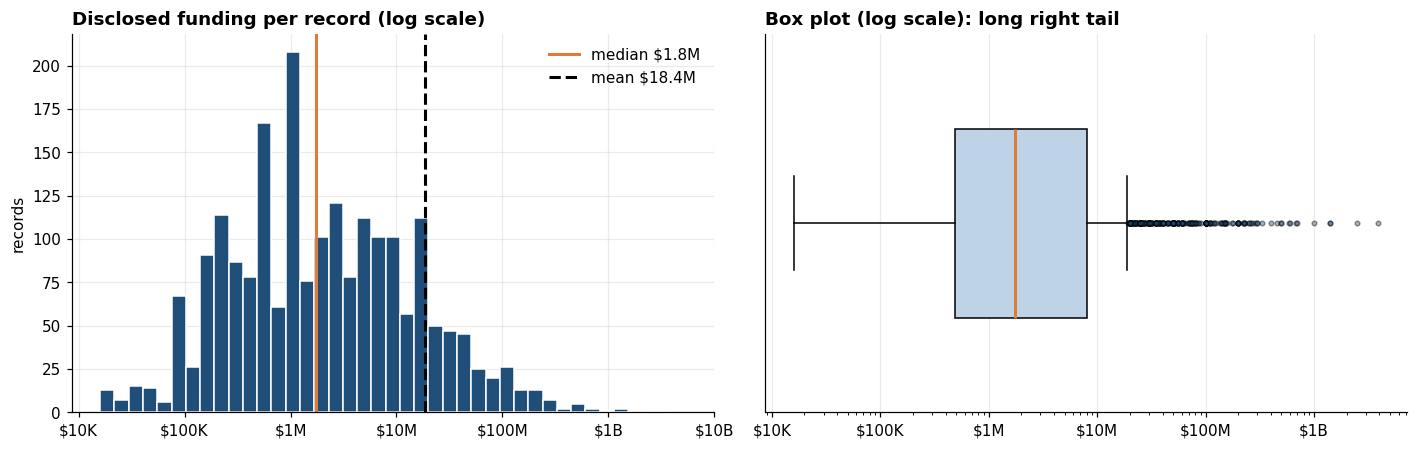

In [12]:
# ---- B. Funding amount distribution (disclosed amounts only) ----
x = df.loc[df["disclosed"], "amount_usd"]
print(f"Disclosed amounts: {len(x):,} of {len(df):,} records ({len(x)/len(df)*100:.1f}%)")
display(x.describe(percentiles=[.01, .05, .1, .25, .5, .75, .9, .95, .99]).to_frame("USD"))

bands = [0, 1e5, 5e5, 1e6, 5e6, 1e7, 5e7, 1e8, 1e9, np.inf]
labels = ["<$100K", "$100K-500K", "$500K-1M", "$1M-5M", "$5M-10M", "$10M-50M", "$50M-100M", "$100M-1B", ">=$1B"]
band = pd.cut(x, bands, labels=labels, right=False)
bt = pd.DataFrame({"records": band.value_counts().reindex(labels),
                   "share_of_records_%": (band.value_counts(normalize=True).reindex(labels) * 100),
                   "total_usd": x.groupby(band).sum().reindex(labels)})
bt["share_of_total_funding_%"] = bt["total_usd"] / x.sum() * 100
display(bt)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
lx = np.log10(x)
ax[0].hist(lx, bins=40, color=PAL["main"], edgecolor="white")
ax[0].axvline(np.log10(x.median()), color=PAL["accent"], lw=2, label=f"median {usd(x.median())}")
ax[0].axvline(np.log10(x.mean()), color="black", lw=2, ls="--", label=f"mean {usd(x.mean())}")
ax[0].set_xticks(range(4, 11)); ax[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: usd(10**v, 0)))
ax[0].set_title("Disclosed funding per record (log scale)", loc="left"); ax[0].set_ylabel("records"); ax[0].legend(frameon=False)
ax[1].boxplot(x, vert=False, widths=.5, patch_artist=True, boxprops=dict(facecolor=PAL["light"]),
              medianprops=dict(color=PAL["accent"], lw=2), flierprops=dict(marker="o", ms=3, alpha=.4, markerfacecolor=PAL["main"]))
ax[1].set_xscale("log"); ax[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: usd(v, 0)))
ax[1].set_yticks([]); ax[1].set_title("Box plot (log scale): long right tail", loc="left")
finish(fig, "01_amount_distribution")

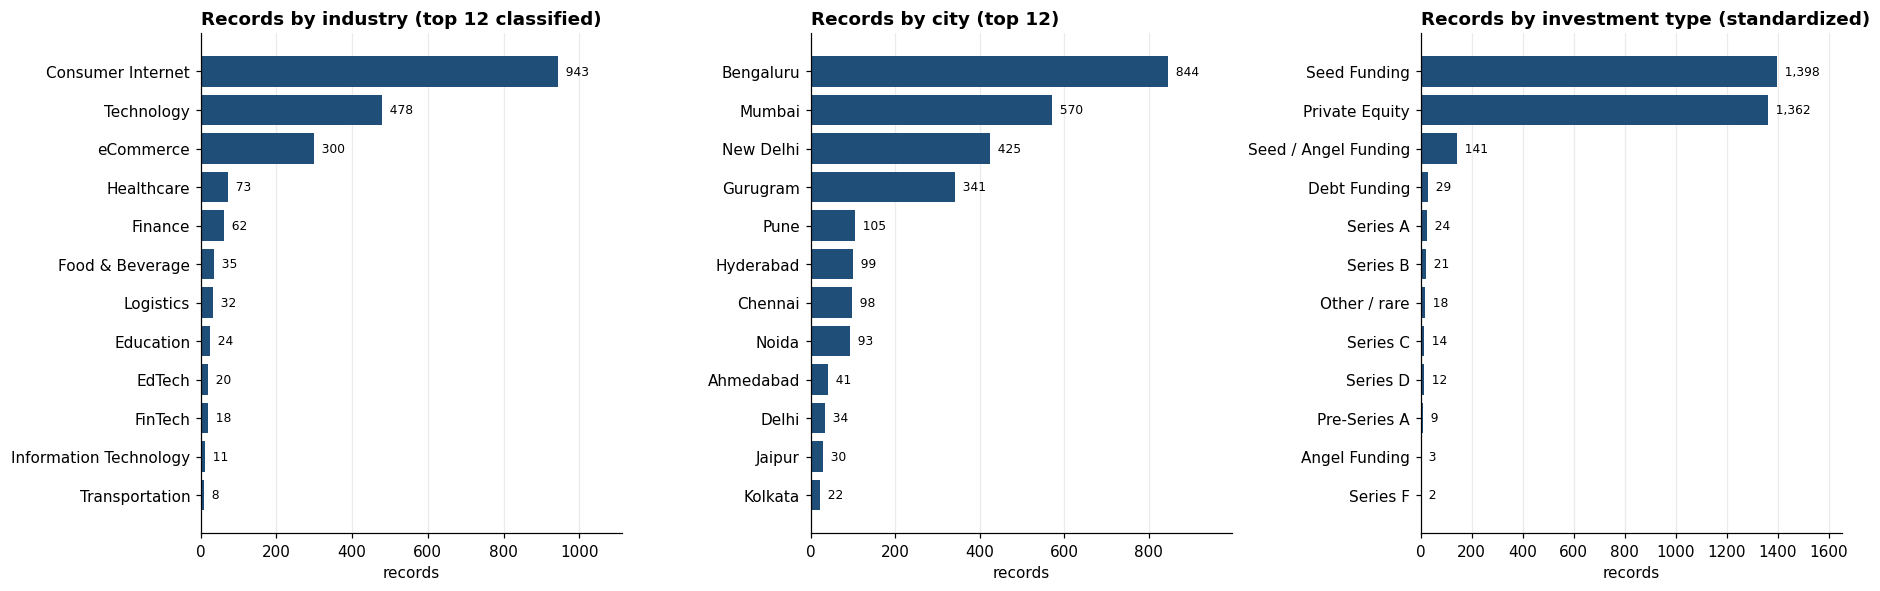

Industry not usable for ranking: Unknown 171 + long-tail 836 + 'Others' 6 = 1,013 records (33.3%)
City not usable for ranking: missing 180 + multi-location 41 + region/country only 9


,records,share_pct
invtype_eda,,
Seed Funding,1398,45.93
Private Equity,1362,44.74
Seed / Angel Funding,141,4.63
Debt Funding,29,0.95
Series A,24,0.79
Series B,21,0.69
Other / rare,18,0.59
Series C,14,0.46
Series D,12,0.39


In [13]:
# ---- C. Industry, city, investment type frequency ----
UNCLASSIFIED = {"Unknown", "Other / long-tail", "Others"}
EXCL_CITY = {"Multiple locations", "Region/country only"}

ind_f = df["industry_group"].value_counts()
city_f = df["city_eda"].value_counts()
type_f = df["invtype_eda"].value_counts()

fig, ax = plt.subplots(1, 3, figsize=(17, 5.5))
barh(ax[0], ind_f.drop(labels=UNCLASSIFIED, errors="ignore").head(12), "Records by industry (top 12 classified)", "records")
barh(ax[1], city_f.drop(labels=EXCL_CITY, errors="ignore").head(12), "Records by city (top 12)", "records")
barh(ax[2], type_f.head(12), "Records by investment type (standardized)", "records")
finish(fig, "02_frequency_industry_city_type")

print(f"Industry not usable for ranking: Unknown {ind_f.get('Unknown',0):,} + long-tail {ind_f.get('Other / long-tail',0):,} + 'Others' {ind_f.get('Others',0):,} "
      f"= {sum(ind_f.get(k,0) for k in UNCLASSIFIED):,} records ({sum(ind_f.get(k,0) for k in UNCLASSIFIED)/len(df)*100:.1f}%)")
print(f"City not usable for ranking: missing {df['city_eda'].isna().sum():,} + multi-location {city_f.get('Multiple locations',0)} + region/country only {city_f.get('Region/country only',0)}")
display(type_f.to_frame("records").assign(share_pct=lambda t: t["records"] / len(df) * 100))

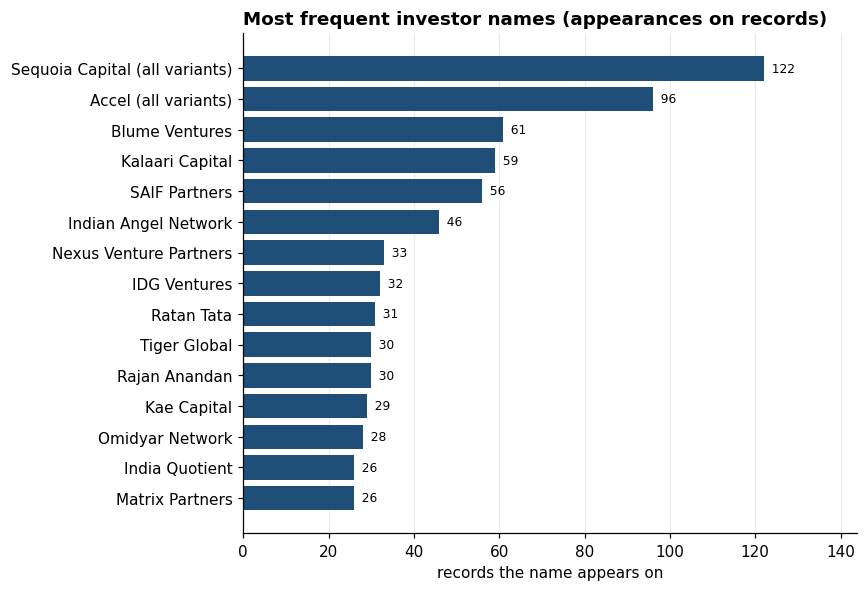

Investor mentions: 5,885 | distinct names: 3,071 | names on a single record only: 2,358 (77%)
The 10 most frequent names account for 9.6% of all investor appearances


In [14]:
# ---- D. Investor frequency (appearances, NOT verified investments) ----
inv_freq = mentions["investor"].value_counts()
fig, ax = plt.subplots(figsize=(8, 5.5))
barh(ax, inv_freq.head(15), "Most frequent investor names (appearances on records)", "records the name appears on")
finish(fig, "03_investor_frequency")
print(f"Investor mentions: {len(mentions):,} | distinct names: {inv_freq.size:,} | names on a single record only: {(inv_freq==1).sum():,} ({(inv_freq==1).mean()*100:.0f}%)")
top10_share = inv_freq.head(10).sum() / len(mentions) * 100
print(f"The 10 most frequent names account for {top10_share:.1f}% of all investor appearances")

Months with ZERO records: ['2019-03']
Records per month: median 53, min 0, max 104


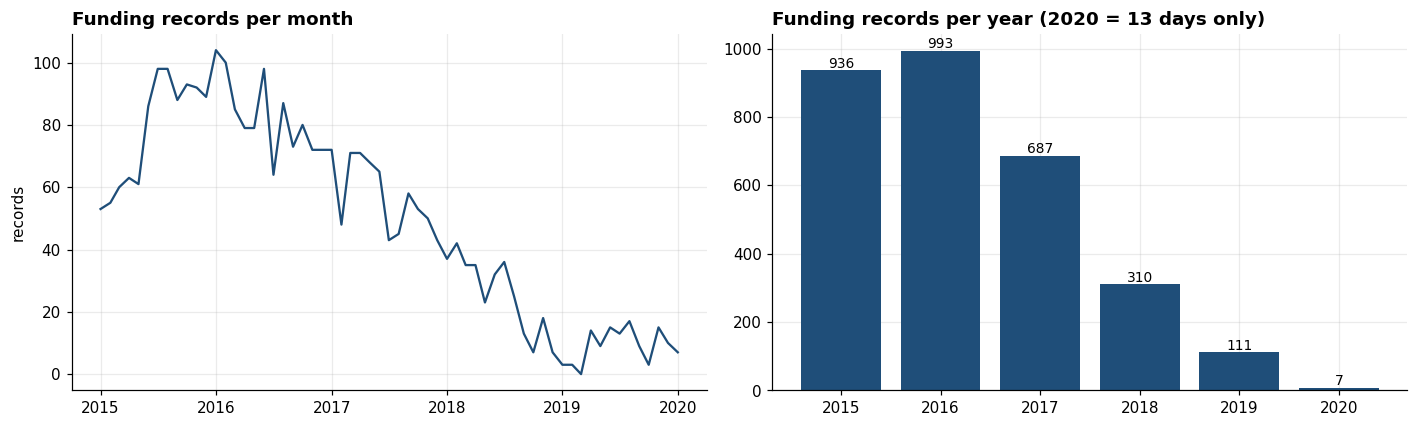

In [15]:
# ---- E. Date coverage ----
months = df.groupby("month").size()
full = pd.period_range(months.index.min(), months.index.max(), freq="M")
months = months.reindex(full, fill_value=0)
print("Months with ZERO records:", [str(m) for m in months[months == 0].index] or "none")
print(f"Records per month: median {months.median():.0f}, min {months.min()}, max {months.max()}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(months.index.to_timestamp(), months.values, color=PAL["main"], lw=1.5)
ax[0].set_title("Funding records per month", loc="left"); ax[0].set_ylabel("records")
yc = df["year"].value_counts().sort_index()
ax[1].bar(yc.index.astype(str), yc.values, color=PAL["main"])
for i, v in enumerate(yc.values): ax[1].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax[1].set_title("Funding records per year (2020 = 13 days only)", loc="left")
finish(fig, "04_date_coverage")

,Amount,Industry,SubVertical,City,Investors,Investment type
year,,,,,,
2015,30.10,18.30,100.00,18.60,3.30,0.00
2016,41.00,0.00,0.00,0.50,5.70,0.10
2017,33.60,0.00,0.00,0.00,4.80,0.00
2018,14.50,0.00,0.00,0.30,4.80,0.00
2019,5.40,0.00,0.00,0.00,2.70,2.70
2020,0.00,0.00,0.00,0.00,0.00,0.00


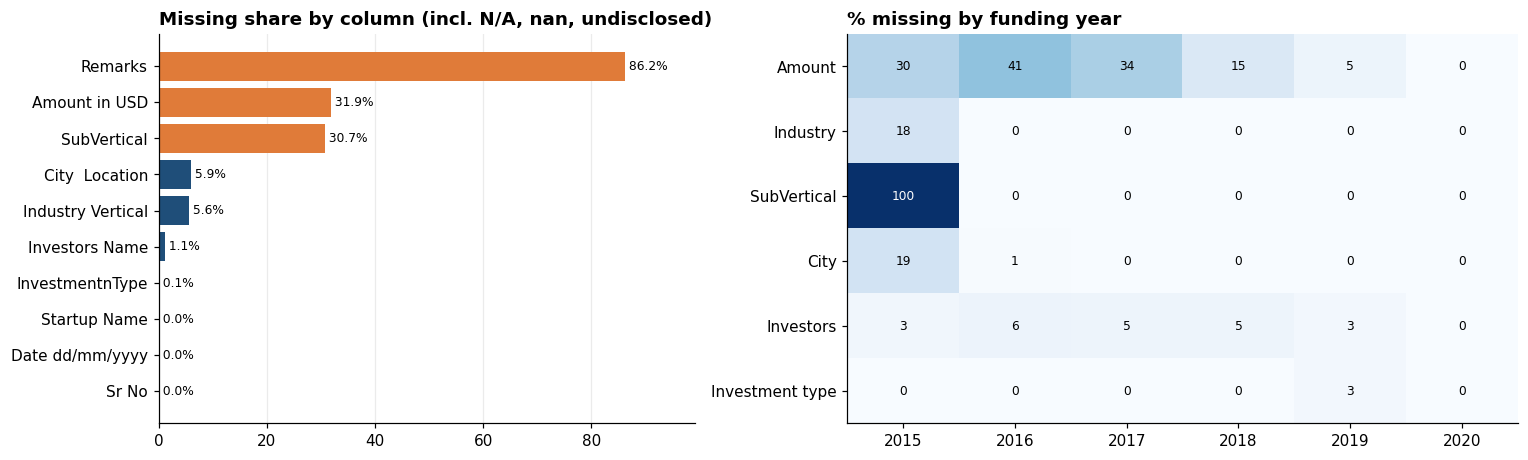

In [16]:
# ---- F. Missing-value distribution ----
flags = pd.DataFrame({
    "Amount": ~df["disclosed"], "Industry": df["industry_eda"].isna(),
    "SubVertical": df["subvertical"].str.lower().isin(PLACEHOLDERS), "City": df["city_eda"].isna(),
    "Investors": inv["n_investors"].eq(0), "Investment type": df["invtype_eda"].isna()})
by_year = flags.groupby(df["year"].astype(int)).mean() * 100
display(by_year.round(1).rename_axis("year"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1, 1.25]})
mm = missing["missing_%"].sort_values()
ax[0].barh(mm.index, mm.values, color=[PAL["accent"] if v > 20 else PAL["main"] for v in mm.values])
for i, v in enumerate(mm.values): ax[0].text(v, i, f" {v:.1f}%", va="center", fontsize=8)
ax[0].set_title("Missing share by column (incl. N/A, nan, undisclosed)", loc="left"); ax[0].grid(axis="y", visible=False); ax[0].margins(x=.15)
im = ax[1].imshow(by_year.T.values, cmap="Blues", aspect="auto", vmin=0, vmax=100)
ax[1].set_xticks(range(len(by_year))); ax[1].set_xticklabels(by_year.index)
ax[1].set_yticks(range(by_year.shape[1])); ax[1].set_yticklabels(by_year.columns)
for i in range(by_year.shape[1]):
    for j in range(by_year.shape[0]):
        v = by_year.iloc[j, i]; ax[1].text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 55 else "black", fontsize=8)
ax[1].set_title("% missing by funding year", loc="left"); ax[1].grid(False)
finish(fig, "05_missing_values")

## 4. Bivariate analysis

Industry, city and investor rankings below exclude unclassified values (Unknown / long-tail / "Others" / multi-location) from the **ranking**, but their share is always reported so the reader can judge coverage. Funding totals use **disclosed amounts only**.

ALL industry groups (incl. unclassified), sorted by disclosed total:


,records,disclosed_records,total_usd,mean_usd,median_usd,max_usd,share_of_all_disclosed_%
industry_group,,,,,,,
Other / long-tail,836,588,"10,445,426,709.68","17,764,331.14","1,725,000.00","700,000,000.00",27.38
eCommerce,300,206,"8,261,735,692.54","40,105,513.07","3,000,000.00","2,500,000,000.00",21.66
Consumer Internet,943,590,"6,254,084,245.00","10,600,142.79","1,000,000.00","330,000,000.00",16.40
Transportation,8,7,"4,068,632,394.00","581,233,199.14","5,000,000.00","3,900,000,000.00",10.67
Technology,478,310,"2,229,707,930.00","7,192,606.23","1,500,000.00","115,000,000.00",5.85
Finance,62,57,"1,971,438,000.00","34,586,631.58","6,240,000.00","600,000,000.00",5.17
FinTech,18,17,"1,368,311,265.00","80,488,897.94","5,000,000.00","1,000,000,000.00",3.59
Unknown,171,131,"1,231,811,368.00","9,403,140.21","1,500,000.00","110,000,000.00",3.23
Health and Wellness,6,6,"490,686,000.00","81,781,000.00","9,000,000.00","450,000,000.00",1.29



Unclassified industries hold 30.7% of all disclosed funding - rankings below cover only the remaining 69.3%.


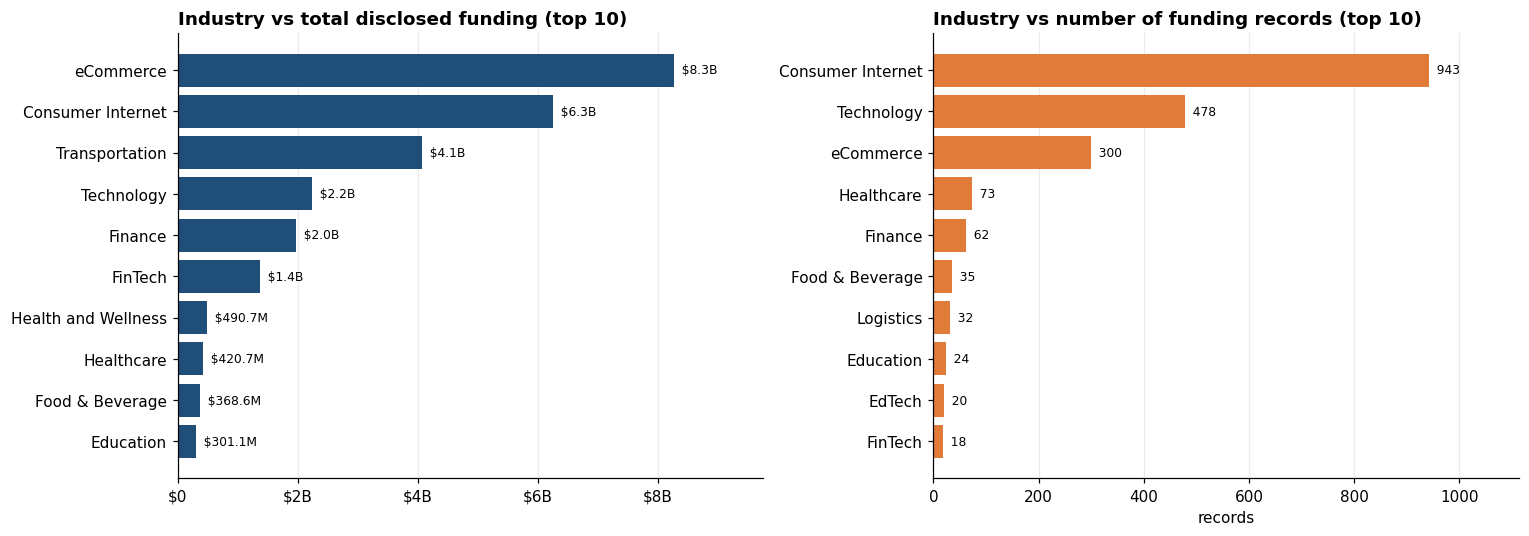

In [17]:
def summarize(g, key):
    out = g.groupby(key).agg(records=("record_id", "count"), disclosed_records=("disclosed", "sum"),
                             total_usd=("amount_usd", "sum"), mean_usd=("amount_usd", "mean"),
                             median_usd=("amount_usd", "median"), max_usd=("amount_usd", "max"))
    out["share_of_all_disclosed_%"] = out["total_usd"] / g["amount_usd"].sum() * 100
    return out

TOTAL = df["amount_usd"].sum()
ind = summarize(df, "industry_group")
print("ALL industry groups (incl. unclassified), sorted by disclosed total:")
display(ind.sort_values("total_usd", ascending=False).head(15))

ind_known = ind.drop(index=list(UNCLASSIFIED & set(ind.index)))
unc_share = ind.loc[list(UNCLASSIFIED & set(ind.index)), "total_usd"].sum() / TOTAL * 100
print(f"\nUnclassified industries hold {unc_share:.1f}% of all disclosed funding - rankings below cover only the remaining {100-unc_share:.1f}%.")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
barh(ax[0], ind_known["total_usd"].nlargest(10), "Industry vs total disclosed funding (top 10)", money=True)
barh(ax[1], ind_known["records"].nlargest(10), "Industry vs number of funding records (top 10)", "records", color=PAL["accent"])
finish(fig, "06_industry_total_vs_records")

,records,disclosed_records,mean_usd,median_usd,max_usd
industry_group,,,,,
FinTech,18,17,"80,488,897.94","5,000,000.00","1,000,000,000.00"
eCommerce,300,206,"40,105,513.07","3,000,000.00","2,500,000,000.00"
Finance,62,57,"34,586,631.58","6,240,000.00","600,000,000.00"
Education,24,19,"15,849,631.58","1,500,000.00","200,000,000.00"
Food & Beverage,35,25,"14,742,047.80","2,000,000.00","200,000,000.00"
EdTech,20,18,"10,749,781.39","886,250.00","150,000,000.00"
Consumer Internet,943,590,"10,600,142.79","1,000,000.00","330,000,000.00"
Logistics,32,23,"10,558,478.26","6,000,000.00","70,000,000.00"
Healthcare,73,46,"9,146,043.48","2,750,000.00","100,000,000.00"


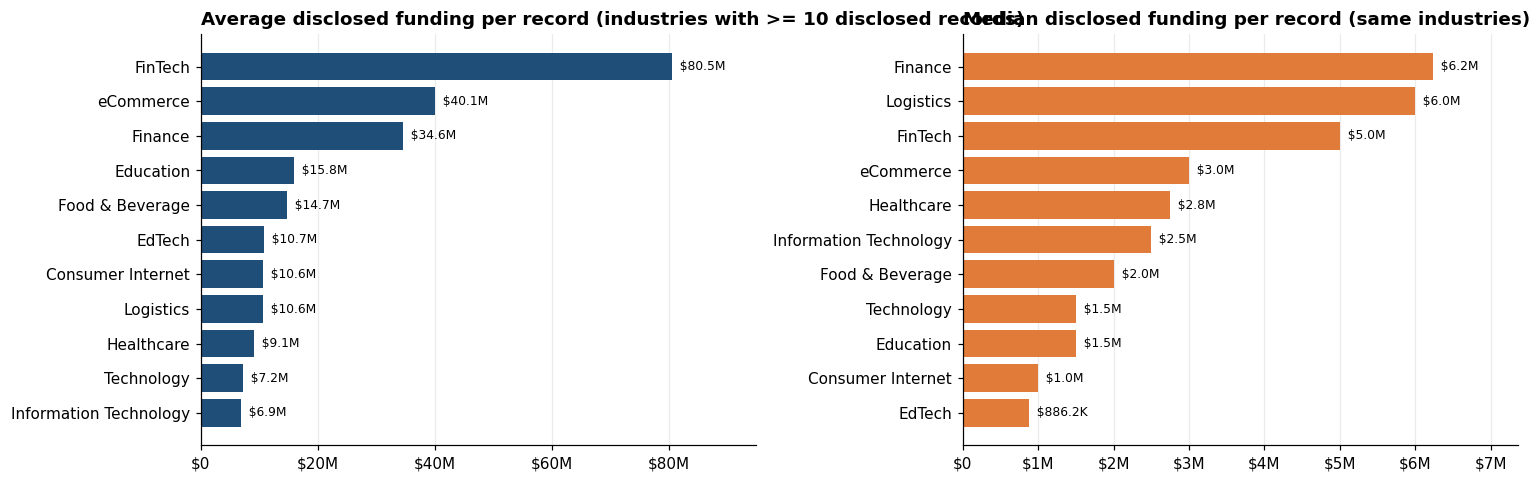

Mean is pulled up by a few mega-deals; the median is the more representative 'typical' deal size.


In [18]:
# Industry vs AVERAGE / MEDIAN disclosed funding (only industries with >= 10 disclosed records)
MIN_N = 10
ia = ind_known[ind_known["disclosed_records"] >= MIN_N].copy()
display(ia[["records", "disclosed_records", "mean_usd", "median_usd", "max_usd"]].sort_values("mean_usd", ascending=False))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
barh(ax[0], ia["mean_usd"], f"Average disclosed funding per record (industries with >= {MIN_N} disclosed records)", money=True)
barh(ax[1], ia["median_usd"], "Median disclosed funding per record (same industries)", money=True, color=PAL["accent"])
finish(fig, "07_industry_mean_vs_median")
print("Mean is pulled up by a few mega-deals; the median is the more representative 'typical' deal size.")

,records,disclosed_records,total_usd,mean_usd,median_usd,max_usd,share_of_all_disclosed_%
city_eda,,,,,,,
Bengaluru,844,586,"18,774,708,863.00","32,038,752.33","2,250,000.00","3,900,000,000.00",49.22
Mumbai,570,404,"4,946,604,620.00","12,244,070.84","2,000,000.00","600,000,000.00",12.97
Gurugram,341,243,"3,876,913,657.54","15,954,377.19","2,500,000.00","250,000,000.00",10.16
New Delhi,425,243,"3,028,416,875.00","12,462,620.88","1,000,000.00","680,000,000.00",7.94
Noida,93,56,"1,282,864,000.00","22,908,285.71","1,000,000.00","1,000,000,000.00",3.36
Chennai,98,76,"756,847,000.00","9,958,513.16","2,500,000.00","100,000,000.00",1.98
Pune,105,71,"633,082,000.00","8,916,647.89","1,100,000.00","100,000,000.00",1.66
Menlo Park,1,1,"450,000,000.00","450,000,000.00","450,000,000.00","450,000,000.00",1.18
Hyderabad,99,72,"401,076,230.00","5,570,503.19","1,000,000.00","73,700,000.00",1.05


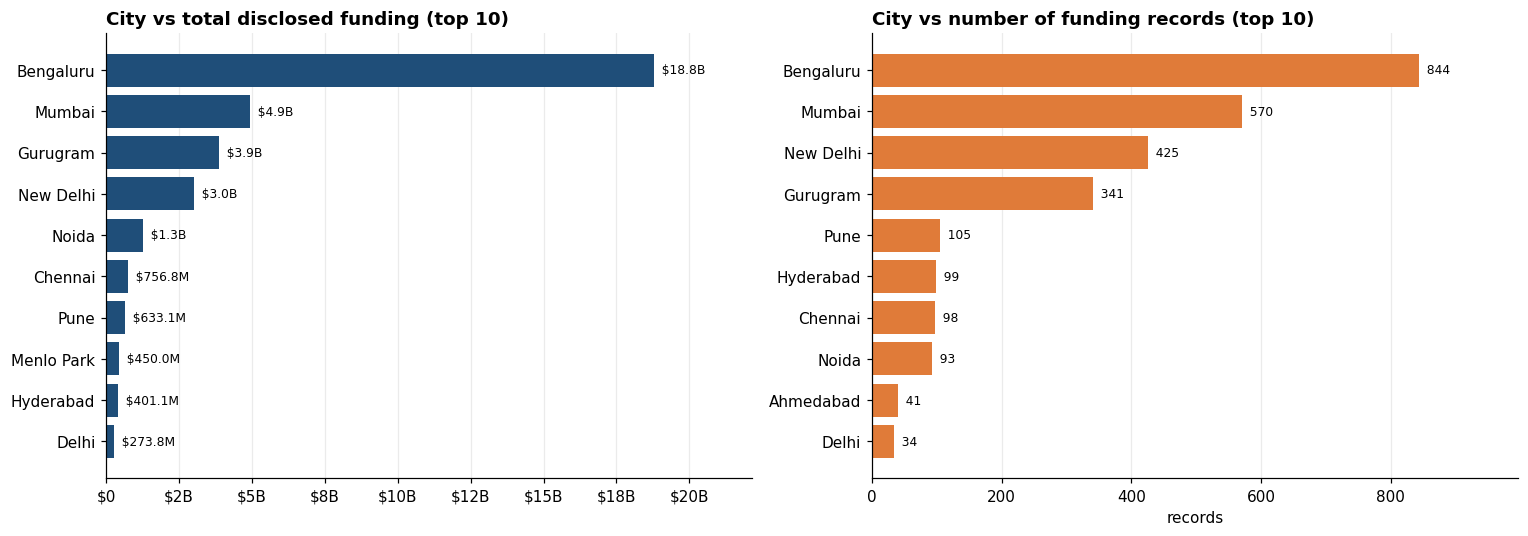

ILLUSTRATIVE ONLY - Delhi-NCR parts shown separately (the EDA keeps them apart; merging them is a Stage 3 modelling decision):


,records,disclosed_records,total_usd
city_eda,,,
Delhi,34,25,"273,754,640.00"
New Delhi,425,243,"3,028,416,875.00"
Gurugram,341,243,"3,876,913,657.54"
Noida,93,56,"1,282,864,000.00"
Faridabad,3,2,"252,000,000.00"


Delhi-NCR combined: 896 records, $8.7B disclosed -> would rank below #1 by total funding.
City missing/unusable: 230 records


In [19]:
# ---- City vs funding ----
city = summarize(df, "city_eda")
city_known = city.drop(index=list(EXCL_CITY & set(city.index)))
display(city_known.sort_values("total_usd", ascending=False).head(12))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
barh(ax[0], city_known["total_usd"].nlargest(10), "City vs total disclosed funding (top 10)", money=True)
barh(ax[1], city_known["records"].nlargest(10), "City vs number of funding records (top 10)", "records", color=PAL["accent"])
finish(fig, "08_city_total_vs_records")

NCR = ["Delhi", "New Delhi", "Gurugram", "Noida", "Faridabad"]
ncr = city.loc[[c for c in NCR if c in city.index], ["records", "disclosed_records", "total_usd"]]
print("ILLUSTRATIVE ONLY - Delhi-NCR parts shown separately (the EDA keeps them apart; merging them is a Stage 3 modelling decision):")
display(ncr)
print(f"Delhi-NCR combined: {ncr['records'].sum():,} records, {usd(ncr['total_usd'].sum())} disclosed "
      f"-> would rank {'1st' if ncr['total_usd'].sum() > city_known['total_usd'].max() else 'below #1'} by total funding.")
print(f"City missing/unusable: {df['city_eda'].isna().sum() + (df['city_eda'].isin(EXCL_CITY)).sum():,} records")

,records,disclosed_records,total_usd,mean_usd,median_usd,max_usd,share_of_all_disclosed_%
invtype_eda,,,,,,,
Seed Funding,1398,752,"830,120,908.00","1,103,884.19","330,000.00","220,000,000.00",2.18
Private Equity,1362,1077,"27,234,868,165.00","25,287,714.17","6,000,000.00","2,500,000,000.00",71.40
Seed / Angel Funding,141,110,"225,696,010.00","2,051,781.91","713,500.00","100,000,000.00",0.59
Debt Funding,29,28,"185,102,354.00","6,610,798.36","4,900,000.00","26,000,000.00",0.49
Series A,24,22,"203,200,000.00","9,236,363.64","4,250,000.00","45,000,000.00",0.53
Series B,21,21,"4,805,195,735.00","228,818,844.52","15,800,000.00","3,900,000,000.00",12.60
Other / rare,18,15,"1,375,592,915.00","91,706,194.33","14,680,000.00","1,000,000,000.00",3.61
Series C,14,14,"1,044,718,394.00","74,622,742.43","50,000,000.00","450,000,000.00",2.74
Series D,12,12,"1,481,799,000.00","123,483,250.00","65,000,000.00","585,000,000.00",3.88


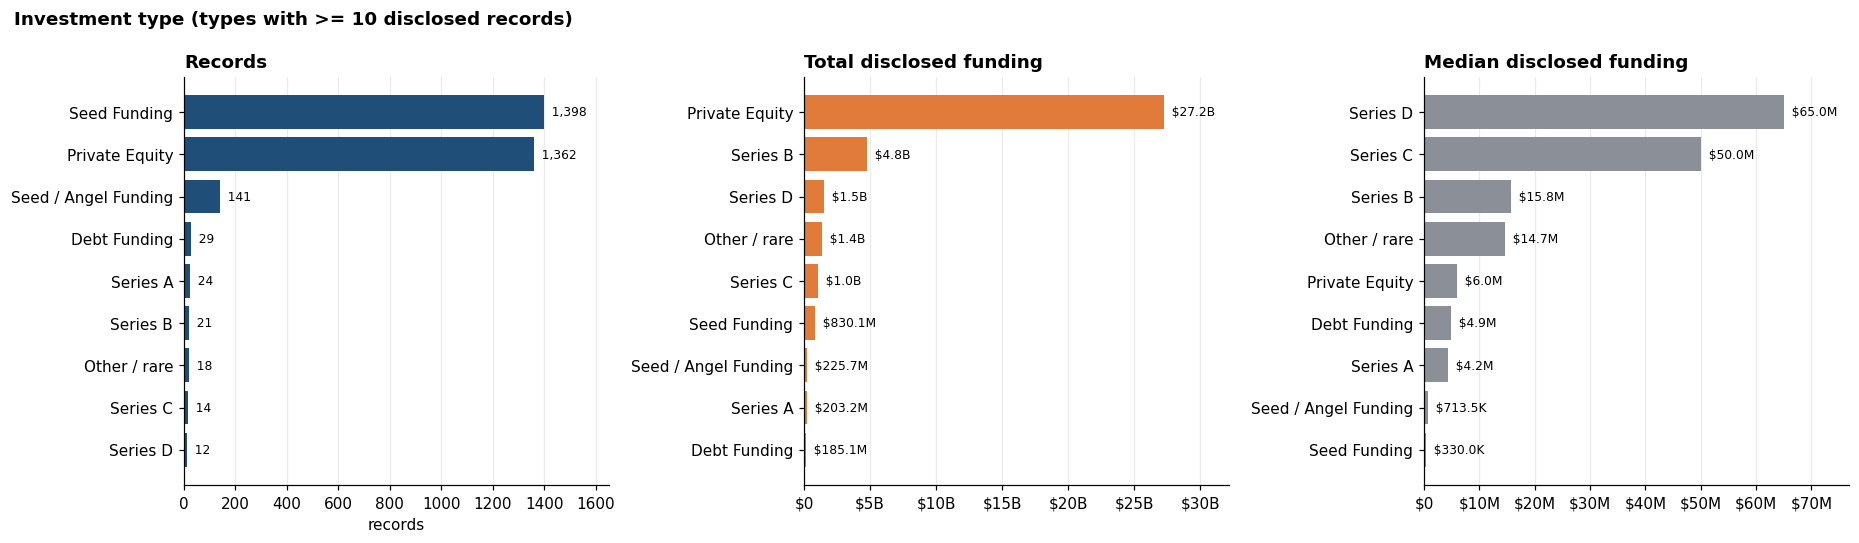

'Private Equity' is a catch-all. The funding STAGE is often only in Remarks:


,records
stage_from_remarks,
(no stage in remarks),1032
Series A,177
Series B,70
Pre-Series A,37
Series C,30
Series D,12
Series E,2
Series F,1
Series G,1


Stage extractable from Remarks for 342 records overall.


In [20]:
# ---- Investment type vs funding ----
it = summarize(df, "invtype_eda").sort_values("records", ascending=False)
display(it)
big = it[it["disclosed_records"] >= 10]
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
barh(ax[0], big["records"], "Records", "records")
barh(ax[1], big["total_usd"], "Total disclosed funding", money=True, color=PAL["accent"])
barh(ax[2], big["median_usd"], "Median disclosed funding", money=True, color=PAL["grey"])
fig.suptitle("Investment type (types with >= 10 disclosed records)", x=0.01, ha="left", fontweight="bold")
finish(fig, "09_investment_type")

print("'Private Equity' is a catch-all. The funding STAGE is often only in Remarks:")
pe = df[df["invtype_eda"] == "Private Equity"]
display(pe["stage_from_remarks"].fillna("(no stage in remarks)").value_counts().to_frame("records"))
print(f"Stage extractable from Remarks for {df['stage_from_remarks'].notna().sum():,} records overall.")

,records,disclosed_records,total_usd,mean_usd,median_usd,max_usd,share_of_all_disclosed_%,disclosed_coverage_%
year,,,,,,,,
2015,936,654,"8,673,022,368.00","13,261,502.09","1,500,000.00","700,000,000.00",22.74,69.87
2016,993,586,"3,828,088,608.00","6,532,574.42","1,000,000.00","200,000,000.00",10.04,59.01
2017,687,456,"10,429,309,730.00","22,871,293.27","2,250,000.00","2,500,000,000.00",27.34,66.38
2018,310,265,"5,122,368,369.00","19,329,691.96","4,000,000.00","600,000,000.00",13.43,85.48
2019,111,105,"9,700,918,535.22","92,389,700.34","12,000,000.00","3,900,000,000.00",25.43,94.59
2020,7,7,"390,207,254.00","55,743,893.43","9,000,000.00","200,000,000.00",1.02,100.00


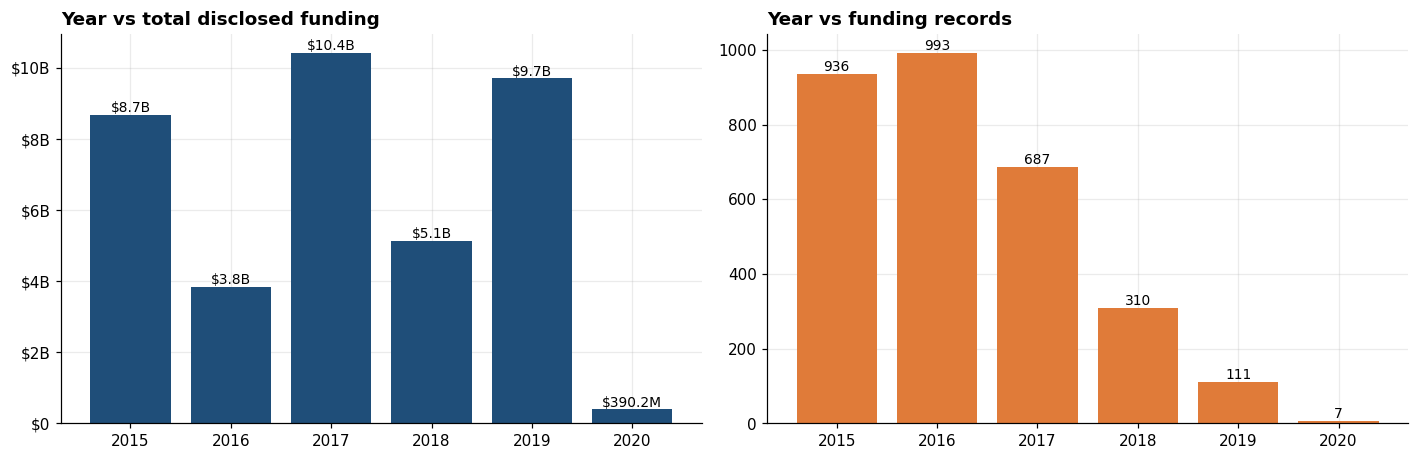

In [21]:
# ---- Year vs funding ----
yr = summarize(df, "year")
yr["disclosed_coverage_%"] = yr["disclosed_records"] / yr["records"] * 100
display(yr)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].bar(yr.index.astype(str), yr["total_usd"], color=PAL["main"])
ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: usd(v, 0)))
for i, v in enumerate(yr["total_usd"]): ax[0].text(i, v, usd(v), ha="center", va="bottom", fontsize=9)
ax[0].set_title("Year vs total disclosed funding", loc="left")
ax[1].bar(yr.index.astype(str), yr["records"], color=PAL["accent"])
for i, v in enumerate(yr["records"]): ax[1].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax[1].set_title("Year vs funding records", loc="left")
finish(fig, "10_year_total_vs_records")

In [22]:
# ---- Investor activity (appearances; amounts are shared with co-investors so they are NOT summed) ----
m = mentions.merge(df[["record_id", "startup_eda", "disclosed"]], on="record_id")
top_inv = (m.groupby("investor").agg(appearances=("record_id", "nunique"), distinct_startups=("startup_eda", "nunique"),
                                     first_year=("year", "min"), last_year=("year", "max"),
                                     median_disclosed_round_usd=("amount_usd", "median"))
             .sort_values("appearances", ascending=False))
top_inv["share_of_records_%"] = top_inv["appearances"] / len(df) * 100
print("Top investor names by appearances (excluding placeholders such as 'Others' and 'Undisclosed'):")
display(top_inv.head(15))
n_ph = inv.loc[inv["investors_raw"].str.lower().isin({"others", "undisclosed investors", "undisclosed"}), "record_id"].count()
print("Interpretation: appearance count measures how often a name is RECORDED, not investment performance, size or success.")

Top investor names by appearances (excluding placeholders such as 'Others' and 'Undisclosed'):


,appearances,distinct_startups,first_year,last_year,median_disclosed_round_usd,share_of_records_%
investor,,,,,,
Sequoia Capital (all variants),122,87,2015,2020,"13,840,000.00",4.01
Accel (all variants),96,68,2015,2019,"8,500,000.00",3.15
Blume Ventures,61,49,2015,2019,"1,275,000.00",2.00
Kalaari Capital,59,46,2015,2019,"3,750,000.00",1.94
SAIF Partners,56,37,2015,2019,"10,000,000.00",1.84
Indian Angel Network,46,44,2015,2019,"510,000.00",1.51
Nexus Venture Partners,33,29,2015,2019,"7,000,000.00",1.08
IDG Ventures,32,24,2015,2018,"2,850,000.00",1.05
Ratan Tata,31,29,2015,2018,"10,200,000.00",1.02


Interpretation: appearance count measures how often a name is RECORDED, not investment performance, size or success.


Top 15 startups by SUM of disclosed amounts across their records (a startup's records may include repeats of one round):


,records,disclosed_records,total_disclosed_usd,largest_single_usd,first,last
startup_eda,,,,,,
Flipkart,6,6,"4,759,700,000.00","2,500,000,000.00",2015-06-04,2017-08-11
Rapido Bike Taxi,1,1,"3,900,000,000.00","3,900,000,000.00",2019-08-27,2019-08-27
Paytm,7,5,"3,148,950,000.00","1,400,000,000.00",2015-02-05,2019-11-25
Ola Cabs,9,8,"1,069,700,000.00","400,000,000.00",2015-04-08,2019-07-03
Ola,4,4,"984,500,000.00","500,000,000.00",2015-11-18,2017-06-14
OYO Rooms,8,8,"897,000,000.00","250,000,000.00",2015-03-25,2018-02-14
Udaan,4,4,"870,000,000.00","585,000,000.00",2016-11-23,2019-10-02
Snapdeal,2,2,"700,000,000.00","500,000,000.00",2015-08-01,2016-02-15
True North,1,1,"600,000,000.00","600,000,000.00",2018-08-30,2018-08-30


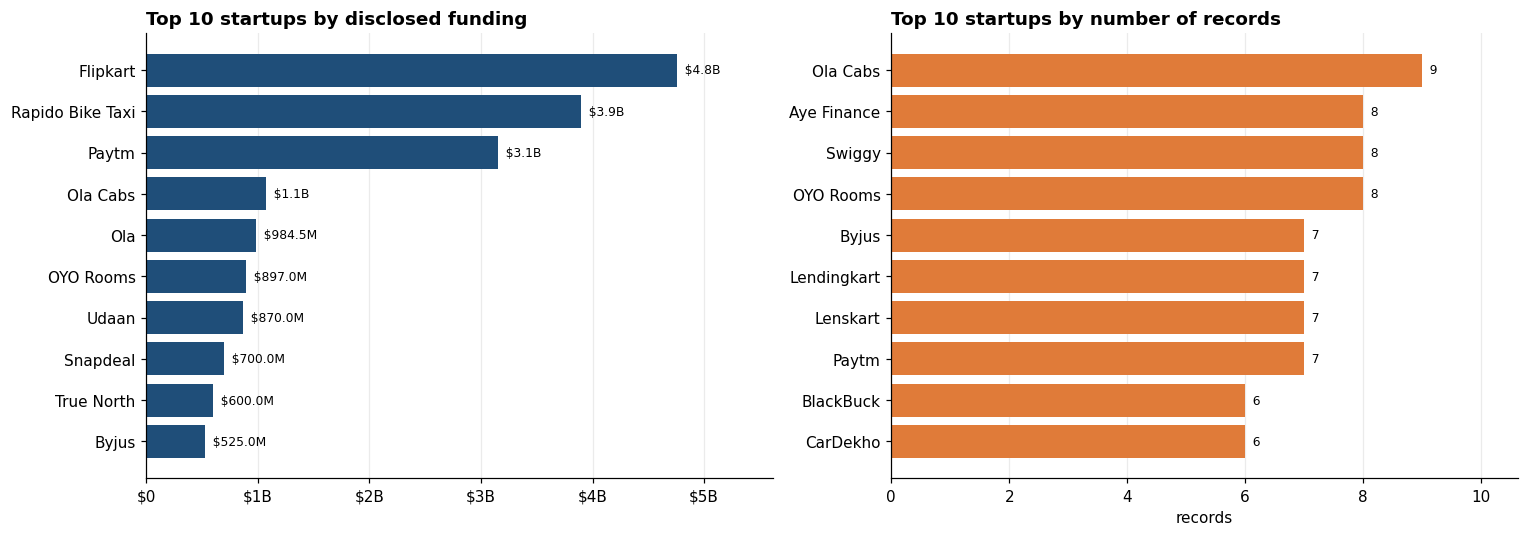

In [23]:
# ---- Startup vs number of recorded events and disclosed funding ----
st = df.groupby("startup_eda").agg(records=("record_id", "count"), disclosed_records=("disclosed", "sum"),
                                   total_disclosed_usd=("amount_usd", "sum"), largest_single_usd=("amount_usd", "max"),
                                   first=("date", "min"), last=("date", "max"))
print("Top 15 startups by SUM of disclosed amounts across their records (a startup's records may include repeats of one round):")
display(st.sort_values("total_disclosed_usd", ascending=False).head(15))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
barh(ax[0], st["total_disclosed_usd"].nlargest(10), "Top 10 startups by disclosed funding", money=True)
barh(ax[1], st["records"].nlargest(10), "Top 10 startups by number of records", "records", color=PAL["accent"])
finish(fig, "11_startup_funding_and_records")

## 5. Time-series analysis

The dates are usable: all 3,044 parse as day/month/year (8 needed separator repairs, listed in section 2). Two cautions apply to every trend below:

1. **Coverage drifts.** The number of records per year falls sharply after 2016, and 2020 contains only 13 days. A fall in *records* may reflect how the dataset was collected, not a real decline in funding.
2. **The share of disclosed amounts changes by year**, so totals are not like-for-like across years.

In [24]:
yr2 = yr.copy()
yr2["records_yoy_%"] = yr2["records"].pct_change() * 100
yr2["total_yoy_%"] = yr2["total_usd"].pct_change() * 100
yr2["median_yoy_%"] = yr2["median_usd"].pct_change() * 100
yr2.loc[2020, ["records_yoy_%", "total_yoy_%", "median_yoy_%"]] = np.nan   # 2020 is a 13-day partial year
display(yr2[["records", "disclosed_records", "disclosed_coverage_%", "total_usd", "median_usd", "records_yoy_%", "total_yoy_%", "median_yoy_%"]])
print("2020 contains only", int((df['year'] == 2020).sum()), "records (1-13 Jan) - its YoY values are intentionally blank.")

,records,disclosed_records,disclosed_coverage_%,total_usd,median_usd,records_yoy_%,total_yoy_%,median_yoy_%
year,,,,,,,,
2015,936,654,69.87,"8,673,022,368.00","1,500,000.00",NaN,NaN,NaN
2016,993,586,59.01,"3,828,088,608.00","1,000,000.00",6.09,-55.86,-33.33
2017,687,456,66.38,"10,429,309,730.00","2,250,000.00",-30.82,172.44,125.00
2018,310,265,85.48,"5,122,368,369.00","4,000,000.00",-54.88,-50.88,77.78
2019,111,105,94.59,"9,700,918,535.22","12,000,000.00",-64.19,89.38,200.00
2020,7,7,100.00,"390,207,254.00","9,000,000.00",NaN,NaN,NaN


2020 contains only 7 records (1-13 Jan) - its YoY values are intentionally blank.


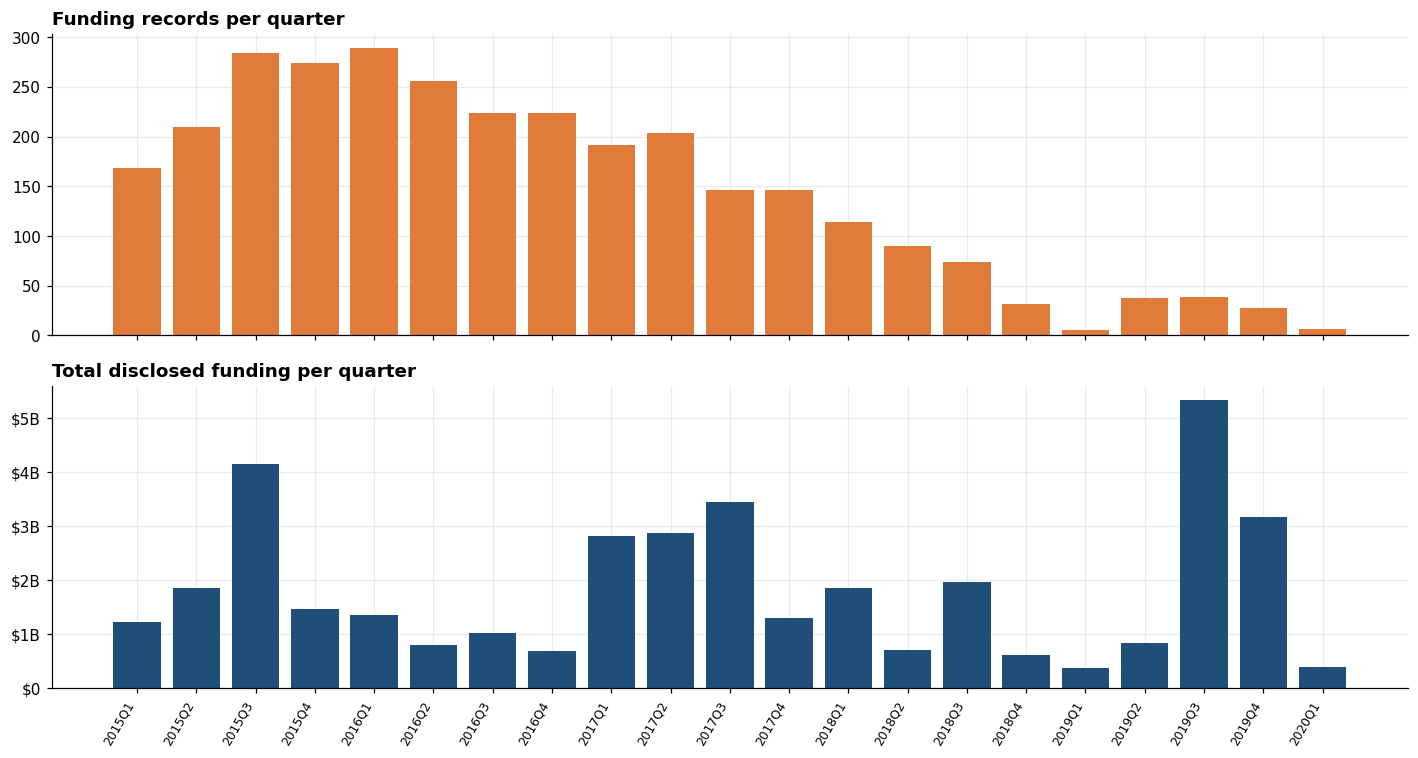

Top 5 quarters by disclosed funding:


,records,total,disclosed
quarter,,,
2019Q3,39,"5,331,364,605.00",38
2015Q3,284,"4,140,993,000.00",196
2017Q3,146,"3,452,345,000.00",89
2019Q4,28,"3,169,697,265.00",26
2017Q2,204,"2,863,882,000.00",134


In [25]:
q = df.groupby("quarter").agg(records=("record_id", "count"), total=("amount_usd", "sum"), disclosed=("disclosed", "sum"))
q.index = q.index.astype(str)
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].bar(q.index, q["records"], color=PAL["accent"]); ax[0].set_title("Funding records per quarter", loc="left")
ax[1].bar(q.index, q["total"], color=PAL["main"]); ax[1].set_title("Total disclosed funding per quarter", loc="left")
ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: usd(v, 0)))
plt.setp(ax[1].get_xticklabels(), rotation=60, ha="right", fontsize=8)
finish(fig, "12_quarterly_trend")
print("Top 5 quarters by disclosed funding:")
display(q.sort_values("total", ascending=False).head(5))

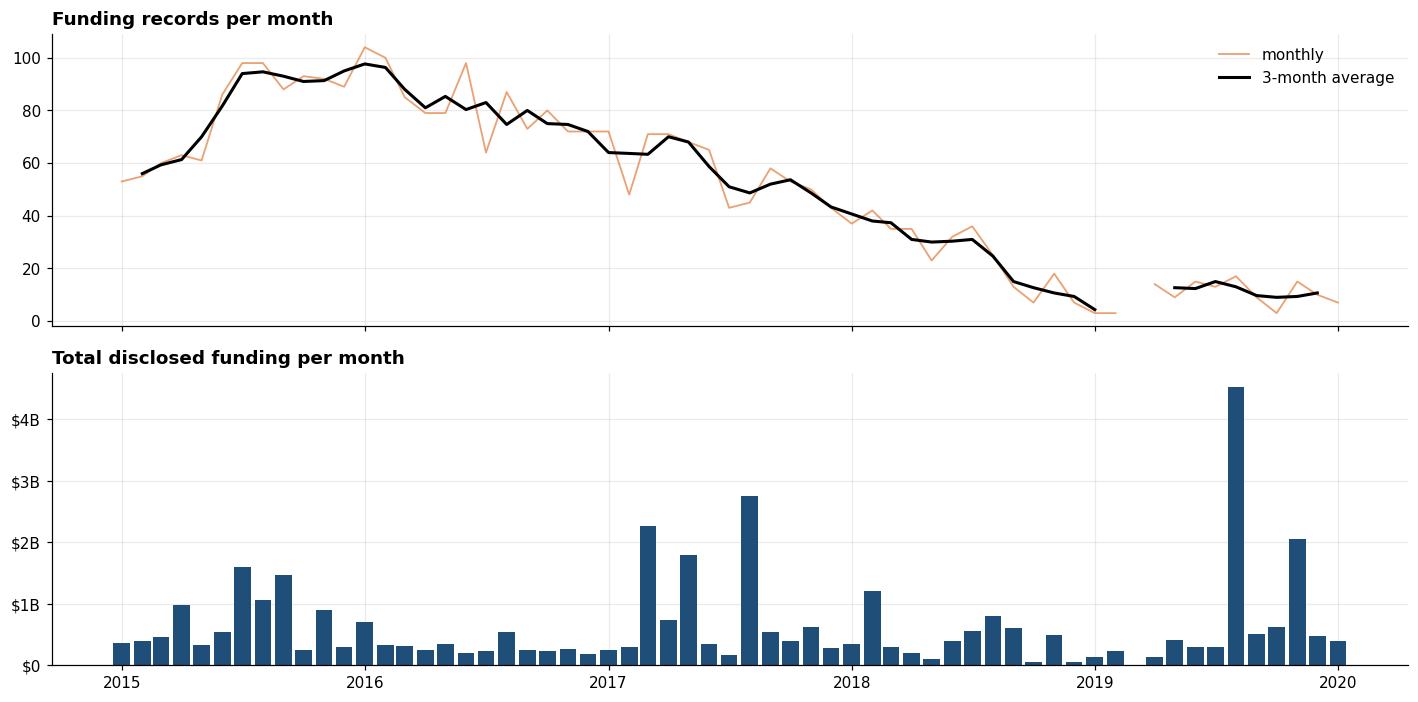

Top 5 months by disclosed funding:


,records,total
2019-08,17.00,"4,531,770,000.00"
2017-08,45.00,"2,748,139,000.00"
2017-03,71.00,"2,264,281,000.00"
2019-11,15.00,"2,062,797,265.00"
2017-05,68.00,"1,786,669,000.00"


In [26]:
mo = df.groupby("month").agg(records=("record_id", "count"), total=("amount_usd", "sum"))
mo = mo.reindex(pd.period_range(mo.index.min(), mo.index.max(), freq="M"))
fig, ax = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
ax[0].plot(mo.index.to_timestamp(), mo["records"], color=PAL["accent"], lw=1.2, alpha=.7, label="monthly")
ax[0].plot(mo.index.to_timestamp(), mo["records"].rolling(3, center=True).mean(), color="black", lw=2, label="3-month average")
ax[0].legend(frameon=False); ax[0].set_title("Funding records per month", loc="left")
ax[1].bar(mo.index.to_timestamp(), mo["total"], width=25, color=PAL["main"]); ax[1].set_title("Total disclosed funding per month", loc="left")
ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: usd(v, 0)))
finish(fig, "13_monthly_trend")
print("Top 5 months by disclosed funding:")
display(mo.sort_values("total", ascending=False).head(5))

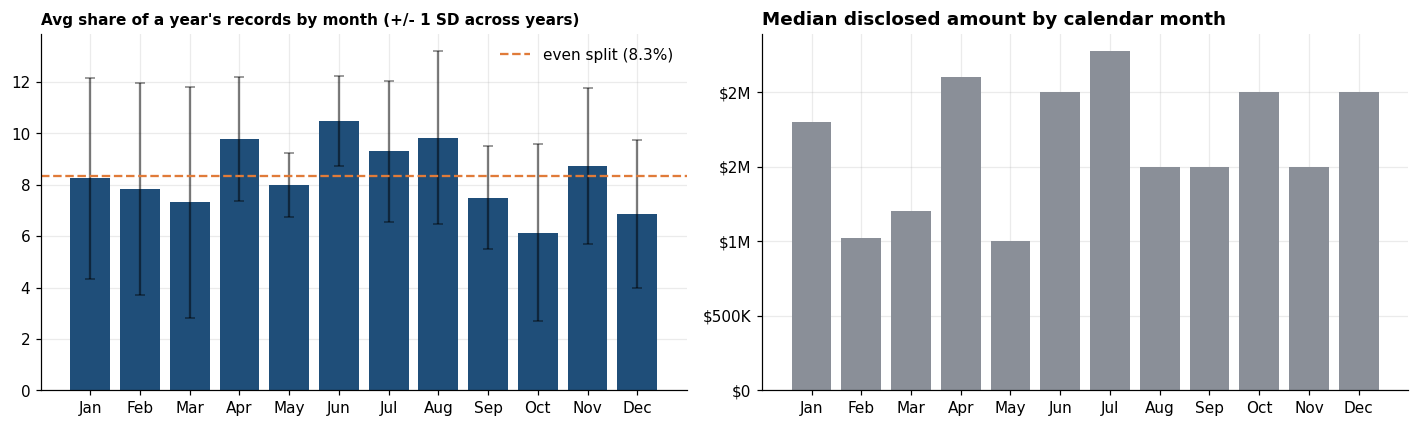

Highest-share month: Jun (10.5%) | lowest: Oct (6.1%) | even split: 8.3%
Typical year-to-year variation of a single month's share (avg SD): 3.0 points
Gap between the highest and lowest month = 4.3 points, only 1.5x the typical year-to-year noise of a single month (3.0 points).
Interpretation: with 5 usable years the month-to-month differences are within noise; the dataset does not support a firm seasonality claim.


In [27]:
# Seasonality: complete calendar years 2015-2019 only; each month expressed as a share of ITS OWN year so big years don't dominate
cy = df[df["year"].between(2015, 2019)]
cnt = cy.groupby(["year", "month_num"]).size().unstack(fill_value=0)
share = cnt.div(cnt.sum(axis=1), axis=0) * 100
avg_share = share.mean(); sd_share = share.std()
med_amt = cy.groupby("month_num")["amount_usd"].median()
names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(names, avg_share.values, yerr=sd_share.values, color=PAL["main"], capsize=3, error_kw=dict(alpha=.5))
ax[0].axhline(100/12, color=PAL["accent"], ls="--", label="even split (8.3%)"); ax[0].legend(frameon=False)
ax[0].set_title("Avg share of a year's records by month (+/- 1 SD across years)", loc="left", fontsize=10)
ax[1].bar(names, med_amt.values, color=PAL["grey"]); ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: usd(v, 0)))
ax[1].set_title("Median disclosed amount by calendar month", loc="left")
finish(fig, "14_seasonality")
print(f"Highest-share month: {names[int(avg_share.idxmax())-1]} ({avg_share.max():.1f}%) | lowest: {names[int(avg_share.idxmin())-1]} ({avg_share.min():.1f}%) | even split: 8.3%")
print(f"Typical year-to-year variation of a single month's share (avg SD): {sd_share.mean():.1f} points")
gap = avg_share.max() - avg_share.min()
print(f"Gap between the highest and lowest month = {gap:.1f} points, only {gap/sd_share.mean():.1f}x the typical year-to-year noise of a single month ({sd_share.mean():.1f} points).")
print("Interpretation: with 5 usable years the month-to-month differences are within noise; the dataset does not support a firm seasonality claim.")

## 6. Statistical analysis

In [28]:
x = df.loc[df["disclosed"], "amount_usd"]
st_tbl = pd.Series({"count": len(x), "mean": x.mean(), "median": x.median(), "min": x.min(), "max": x.max(),
                    "std": x.std(), "coefficient of variation": x.std() / x.mean(), "skewness": x.skew(), "excess kurtosis": x.kurt(),
                    "mean / median": x.mean() / x.median()})
display(st_tbl.to_frame("disclosed amounts (USD)"))
pcts = x.quantile([.01, .05, .10, .25, .50, .75, .90, .95, .99]); pcts.index = [f"P{int(p*100)}" for p in pcts.index]
display(pcts.to_frame("USD"))

# Outliers: IQR on the raw scale AND on the log scale (more suitable for a heavily right-skewed variable)
q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1; up_raw = q3 + 1.5 * iqr
lx = np.log10(x); lq1, lq3 = lx.quantile([.25, .75]); lup = lq3 + 1.5 * (lq3 - lq1); llo = lq1 - 1.5 * (lq3 - lq1)
o_raw = x[x > up_raw]; o_log_hi = x[np.log10(x) > lup]; o_log_lo = x[np.log10(x) < llo]
print(f"IQR rule, raw scale : upper fence {usd(up_raw)} -> {len(o_raw)} records ({len(o_raw)/len(x)*100:.1f}%) hold {o_raw.sum()/x.sum()*100:.1f}% of disclosed funding")
print(f"IQR rule, log scale : upper fence {usd(10**lup)} -> {len(o_log_hi)} high outliers; lower fence {usd(10**llo)} -> {len(o_log_lo)} low outliers")
print("Interpretation: the raw-scale rule flags many ordinary large deals because the distribution is log-normal-like; the log-scale rule isolates the truly extreme ones.")
print("\nExtreme records to INVESTIGATE (not deleted), amounts above the log-scale fence:")
ext = df.loc[o_log_hi.index, ["record_id", "date", "startup_eda", "industry_eda", "invtype_eda", "amount_usd"]].sort_values("amount_usd", ascending=False)
display(ext.head(15))

,disclosed amounts (USD)
count,"2,073.00"
mean,"18,400,344.85"
median,"1,750,000.00"
min,"16,000.00"
max,"3,900,000,000.00"
std,"121,140,713.40"
coefficient of variation,6.58
skewness,22.18
excess kurtosis,612.82
mean / median,10.51


,USD
P1,"30,000.00"
P5,"100,000.00"
P10,"156,800.00"
P25,"486,000.00"
P50,"1,750,000.00"
P75,"8,000,000.00"
P90,"27,959,800.00"
P95,"60,000,000.00"
P99,"236,320,000.00"


IQR rule, raw scale : upper fence $19.3M -> 285 records (13.7%) hold 85.1% of disclosed funding
IQR rule, log scale : upper fence $534.3M -> 9 high outliers; lower fence $7.3K -> 0 low outliers
Interpretation: the raw-scale rule flags many ordinary large deals because the distribution is log-normal-like; the log-scale rule isolates the truly extreme ones.

Extreme records to INVESTIGATE (not deleted), amounts above the log-scale fence:


,record_id,date,startup_eda,industry_eda,invtype_eda,amount_usd
60,61,2019-08-27,Rapido Bike Taxi,Transportation,Series B,"3,900,000,000.00"
651,652,2017-08-11,Flipkart,eCommerce,Private Equity,"2,500,000,000.00"
966,967,2017-03-21,Flipkart,eCommerce,Private Equity,"1,400,000,000.00"
830,831,2017-05-18,Paytm,eCommerce,Private Equity,"1,400,000,000.00"
31,32,2019-11-25,Paytm,FinTech,Other / rare,"1,000,000,000.00"
2648,2649,2015-07-28,Flipkart,Online Marketplace,Private Equity,"700,000,000.00"
2459,2460,2015-09-29,Paytm,E-Commerce & M-Commerce platform,Private Equity,"680,000,000.00"
188,189,2018-08-30,True North,Finance,Private Equity,"600,000,000.00"
33,34,2019-10-02,Udaan,B2B,Series D,"585,000,000.00"


In [29]:
# Concentration
tot = df["amount_usd"].sum()
srt = df["amount_usd"].dropna().sort_values(ascending=False)
print(f"Largest single record        : {usd(srt.iloc[0])} = {srt.iloc[0]/tot*100:.1f}% of all disclosed funding")
print(f"Top 10 records               : {usd(srt.head(10).sum())} = {srt.head(10).sum()/tot*100:.1f}%")
print(f"Top 1% of disclosed records  : {srt.head(int(len(srt)*.01)).sum()/tot*100:.1f}% of funding ({int(len(srt)*.01)} records)")
print(f"Top 10% of disclosed records : {srt.head(int(len(srt)*.10)).sum()/tot*100:.1f}% of funding ({int(len(srt)*.10)} records)")
print(f"Bottom 50% of disclosed rec. : {srt.tail(len(srt)//2).sum()/tot*100:.1f}% of funding")

st_sorted = st["total_disclosed_usd"].sort_values(ascending=False)
print(f"\nTop 10 startups              : {st_sorted.head(10).sum()/tot*100:.1f}% of disclosed funding")
ik = ind_known["total_usd"].sort_values(ascending=False)
print(f"Top 3 classified industries  : {ik.head(3).sum()/tot*100:.1f}% | top 5: {ik.head(5).sum()/tot*100:.1f}% of ALL disclosed funding")
sh = ik / ik.sum()
print(f"Industry HHI (classified only): {(sh**2).sum()*10000:,.0f}  (>2,500 is conventionally 'highly concentrated')")
ck = city_known["total_usd"].sort_values(ascending=False)
print(f"Top 3 cities                 : {ck.head(3).sum()/tot*100:.1f}% | top 5: {ck.head(5).sum()/tot*100:.1f}% of ALL disclosed funding")
print(f"Top 10 investor names        : {inv_freq.head(10).sum()/len(mentions)*100:.1f}% of investor appearances")

Largest single record        : $3.9B = 10.2% of all disclosed funding
Top 10 records               : $13.3B = 34.8%
Top 1% of disclosed records  : 43.5% of funding (20 records)
Top 10% of disclosed records : 80.4% of funding (207 records)
Bottom 50% of disclosed rec. : 1.5% of funding

Top 10 startups              : 45.8% of disclosed funding
Top 3 classified industries  : 48.7% | top 5: 59.7% of ALL disclosed funding
Industry HHI (classified only): 1,936  (>2,500 is conventionally 'highly concentrated')
Top 3 cities                 : 72.4% | top 5: 83.7% of ALL disclosed funding
Top 10 investor names        : 9.6% of investor appearances


In [30]:
# Sensitivity: how much do the headline numbers depend on ONE suspicious record?
top = df.loc[df["amount_usd"].idxmax()]
print("Largest record in the file:")
display(top[["record_id", "date", "startup_eda", "industry_eda", "city_eda", "invtype_eda", "amount_usd"]].to_frame("value"))
wo = df.drop(index=df["amount_usd"].idxmax())
cmp = pd.DataFrame({
    "with it":    [df["amount_usd"].sum(), df["amount_usd"].mean(), df["amount_usd"].median(), df.loc[df["year"] == top["year"], "amount_usd"].sum()],
    "without it": [wo["amount_usd"].sum(), wo["amount_usd"].mean(), wo["amount_usd"].median(), wo.loc[wo["year"] == top["year"], "amount_usd"].sum()],
}, index=["Total disclosed", "Mean disclosed", "Median disclosed", f"Total disclosed in {int(top['year'])}"])
cmp["change_%"] = (cmp["without it"] / cmp["with it"] - 1) * 100
display(cmp)
print("The median barely moves; the total, the mean and that year's total are materially affected. Report the median alongside the mean and verify this record at source.")

Largest record in the file:


,value
record_id,61
date,2019-08-27 00:00:00
startup_eda,Rapido Bike Taxi
industry_eda,Transportation
city_eda,Bengaluru
invtype_eda,Series B
amount_usd,"3,900,000,000.00"


,with it,without it,change_%
Total disclosed,"38,143,914,864.22","34,243,914,864.22",-10.22
Mean disclosed,"18,400,344.85","16,526,985.94",-10.18
Median disclosed,"1,750,000.00","1,750,000.00",0.00
Total disclosed in 2019,"9,700,918,535.22","5,800,918,535.22",-40.20


The median barely moves; the total, the mean and that year's total are materially affected. Report the median alongside the mean and verify this record at source.


### Is the trend real, or is the record mix changing?
Records fall from 936 (2015) to 111 (2019) while the median disclosed amount rises. Before reading that as market growth, check whether the *type* of record in the file changes over time.

In [31]:
grp = df["invtype_eda"].fillna("Unknown").where(df["invtype_eda"].fillna("Unknown").isin(["Seed Funding", "Private Equity", "Seed / Angel Funding"]), "All other types")
mix = pd.crosstab(df["year"], grp, normalize="index") * 100
mix["records"] = df["year"].value_counts().sort_index()
print("Share of each year's records by investment type (%):")
display(mix.round(1))

print("Median disclosed amount by year and investment type (like-for-like view):")
piv = df.pivot_table(index="year", columns=grp, values="amount_usd", aggfunc="median")
display(piv)
pe_n = df[df["invtype_eda"] == "Private Equity"].groupby("year")["amount_usd"].agg(["count", "median"])
print("Private Equity only - disclosed count and median per year:")
display(pe_n)

Share of each year's records by investment type (%):


invtype_eda,All other types,Private Equity,Seed / Angel Funding,Seed Funding,records
year,,,,,
2015,0.20,46.50,0.00,53.30,936
2016,0.10,40.90,0.00,59.00,993
2017,1.70,53.10,2.90,42.20,687
2018,11.00,48.40,38.70,1.90,310
2019,81.10,3.60,0.90,14.40,111
2020,57.10,28.60,0.00,14.30,7


Median disclosed amount by year and investment type (like-for-like view):


invtype_eda,All other types,Private Equity,Seed / Angel Funding,Seed Funding
year,,,,
2015,"77,884.00","6,550,000.00",NaN,"350,000.00"
2016,NaN,"4,000,000.00",NaN,"275,000.00"
2017,"2,900,000.00","5,000,000.00","250,000.00","400,000.00"
2018,"4,750,000.00","10,050,000.00","1,000,000.00","489,000.00"
2019,"15,650,000.00","11,500,000.00","307,000.00","1,400,000.00"
2020,"8,524,197.00","175,000,000.00",NaN,"1,800,000.00"


Private Equity only - disclosed count and median per year:


,count,median
year,,
2015,352,"6,550,000.00"
2016,293,"4,000,000.00"
2017,292,"5,000,000.00"
2018,134,"10,050,000.00"
2019,4,"11,500,000.00"
2020,2,"175,000,000.00"


In [32]:
# Where does the unclassified industry data sit? (evidence for the industry limitation)
cls = np.where(df["industry_group"].isin(UNCLASSIFIED), "Unclassified", "Classified")
ct = pd.crosstab(df["year"], cls); ct["unclassified_%"] = ct["Unclassified"] / ct.sum(axis=1) * 100
display(ct.round(1))
print("Unclassified = Unknown + long-tail + 'Others'. Rows from 2015 are the main source: they carry blank industries or free-text descriptions instead of an industry label.")
nonind = df["city_eda"].isin(["Singapore", "San Francisco", "Menlo Park", "Palo Alto", "Santa Monica", "Burnsville", "Nairobi", "New York", "London", "Seattle", "Boston", "San Jose", "Tulangan"]).sum()
print(f"Records whose city is clearly outside India (sample list): {nonind} - e.g. Menlo Park and Tulangan carry $450M and $200M. Decide in Stage 3 whether these belong in an 'Indian startup' view.")

col_0,Classified,Unclassified,unclassified_%
year,,,
2015,18,918,98.10
2016,981,12,1.20
2017,681,6,0.90
2018,280,30,9.70
2019,67,44,39.60
2020,4,3,42.90


Unclassified = Unknown + long-tail + 'Others'. Rows from 2015 are the main source: they carry blank industries or free-text descriptions instead of an industry label.
Records whose city is clearly outside India (sample list): 20 - e.g. Menlo Park and Tulangan carry $450M and $200M. Decide in Stage 3 whether these belong in an 'Indian startup' view.


## 7. The ten business questions — answered from the data

All figures below are printed by code from the working view. Funding is **disclosed amounts only**.

In [33]:
def line(n, r, extra=""): print(f"   {n:<28}{usd(r['total_usd']):>9}  {r['share_of_all_disclosed_%']:>5.1f}% of disclosed  | {int(r['records']):,} records{extra}")

print("Q1. Which industries attract the most DISCLOSED funding? (classified industries only)")
for n, r in ind_known.sort_values("total_usd", ascending=False).head(5).iterrows(): line(n, r)
tr = ind_known.loc["Transportation", "total_usd"]
print(f"   Caution: Transportation's {usd(tr)} is {3.9e9/tr*100:.0f}% a single $3.9B record; without it the industry holds {usd(tr-3.9e9)}.")
print(f"   {unc_share:.1f}% of disclosed funding sits in industries that are unknown / long-tail and cannot be ranked.\n")

print("Q2. Which cities have the highest funding activity?")
print("   By total disclosed funding:")
for n, r in city_known.sort_values("total_usd", ascending=False).head(5).iterrows(): line(n, r)
print("   By number of records:", ", ".join(f"{n} ({int(v):,})" for n, v in city_known["records"].nlargest(5).items()))
b = city_known.loc["Bengaluru", "total_usd"]
print(f"   Bengaluru excluding the $3.9B Rapido record: {usd(b-3.9e9)} = {(b-3.9e9)/(TOTAL-3.9e9)*100:.1f}% of the remaining total\n")

print("Q3. Which investment types are most common? (standardized labels)")
for n, v in type_f.head(5).items(): print(f"   {n:<28}{v:>6,} records ({v/len(df)*100:.1f}%)")
print(f"   Seed Funding + Private Equity together: {(type_f['Seed Funding']+type_f['Private Equity'])/len(df)*100:.1f}% of records\n")

print("Q4. Which investors appear most frequently? (APPEARANCES on records, not verified investments)")
for n, r in top_inv.head(5).iterrows(): print(f"   {n:<34}{int(r['appearances']):>4} records, {int(r['distinct_startups'])} startups")
print(f"   (placeholder values 'Others'/'Undisclosed' were excluded; they appear on {n_ph} records)\n")

print("Q5. How has funding activity changed over time?")
for y, r in yr2.iterrows():
    print(f"   {y}: {int(r['records']):>4} records | disclosed {r['disclosed_coverage_%']:>5.1f}% | total {usd(r['total_usd']):>7} | median {usd(r['median_usd']):>7}"
          + ("  (13 days only)" if y == 2020 else ""))
print("   Record counts fall every year after 2016, but coverage and median rise: the file's composition changes (see the mix table above).\n")

print("Q6. Which startups have the highest recorded funding amounts? (sum of disclosed amounts across their records)")
for n, r in st.sort_values("total_disclosed_usd", ascending=False).head(5).iterrows():
    print(f"   {n:<24}{usd(r['total_disclosed_usd']):>8}  over {int(r['disclosed_records'])} disclosed records (largest {usd(r['largest_single_usd'])})")
ola = st.loc[["Ola", "Ola Cabs"], "total_disclosed_usd"].sum()
print(f"   Note: 'Ola' and 'Ola Cabs' are listed separately; together they would total {usd(ola)}. Flagged for Stage 3 - not merged without evidence.\n")

print("Q7. Which industries have the highest AVERAGE disclosed funding? (>= 10 disclosed records)")
for n, r in ia.sort_values("mean_usd", ascending=False).head(3).iterrows():
    print(f"   {n:<20} mean {usd(r['mean_usd']):>7} | median {usd(r['median_usd']):>7} | n={int(r['disclosed_records'])}")
_t = ia.sort_values("mean_usd", ascending=False).head(3); _g = (_t["mean_usd"] / _t["median_usd"])
print(f"   Means are driven by a handful of mega-deals (mean/median gap is {_g.min():.0f}-{_g.max():.0f}x for these three); medians rank industries differently:")
for n, r in ia.sort_values("median_usd", ascending=False).head(3).iterrows():
    print(f"   {n:<20} median {usd(r['median_usd']):>7} | mean {usd(r['mean_usd']):>7} | n={int(r['disclosed_records'])}")
print()

print("Q8. How much of the dataset has missing / undisclosed amounts?")
nm = (~df["disclosed"]).sum()
print(f"   {nm:,} of {len(df):,} records ({nm/len(df)*100:.1f}%) have no usable amount; {df['disclosed'].sum():,} are disclosed.")
print(f"   Missing share by type: Seed Funding {(~df[df['invtype_eda']=='Seed Funding']['disclosed']).mean()*100:.1f}% vs Private Equity {(~df[df['invtype_eda']=='Private Equity']['disclosed']).mean()*100:.1f}%")
print(f"   Missing share by year: " + ", ".join(f"{y}: {v:.0f}%" for y, v in by_year['Amount'].items()) + "\n")

print("Q9. Main data limitations")
lims = [
 f"Amount missing on {nm/len(df)*100:.1f}% of records; missingness is uneven (seed deals and 2016-17 lose the most), so totals are not like-for-like.",
 f"Record counts collapse over time ({int(yr.loc[2015,'records'])} in 2015 -> {int(yr.loc[2019,'records'])} in 2019; 2020 = 13 days): coverage, not the market, may drive the trend.",
 f"Industry is unusable for {sum(ind_f.get(k,0) for k in UNCLASSIFIED)/len(df)*100:.1f}% of records (2015 rows hold free-text descriptions or are blank); SubVertical is missing for 100% of 2015.",
 f"Heavy skew: mean is {x.mean()/x.median():.1f}x the median; the top 10 records hold {srt.head(10).sum()/tot*100:.1f}% of all disclosed funding.",
 f"{(inv['n_investors']>=2).mean()*100:.1f}% of records list several investors, so investor counts are appearances, and names are spelled inconsistently.",
 "A record is not a verified round: the same round may be listed more than once, and startup names have spelling variants (e.g. Ola / Ola Cabs).",
 "One record ($3.9B, labelled Series B) is far above all others and needs source verification.",
]
for i, l in enumerate(lims, 1): print(f"   {i}. {l}")
print("\nQ10. Business implications -> see the written findings in section 8.")

Q1. Which industries attract the most DISCLOSED funding? (classified industries only)
   eCommerce                       $8.3B   21.7% of disclosed  | 300 records
   Consumer Internet               $6.3B   16.4% of disclosed  | 943 records
   Transportation                  $4.1B   10.7% of disclosed  | 8 records
   Technology                      $2.2B    5.8% of disclosed  | 478 records
   Finance                         $2.0B    5.2% of disclosed  | 62 records
   Caution: Transportation's $4.1B is 96% a single $3.9B record; without it the industry holds $168.6M.
   30.7% of disclosed funding sits in industries that are unknown / long-tail and cannot be ranked.

Q2. Which cities have the highest funding activity?
   By total disclosed funding:
   Bengaluru                      $18.8B   49.2% of disclosed  | 844 records
   Mumbai                          $4.9B   13.0% of disclosed  | 570 records
   Gurugram                        $3.9B   10.2% of disclosed  | 341 records
   New Delhi 

## 8. Evidence-based findings

Each finding states **what the data shows → the supporting metric → why it matters → the limitation**. All numbers appear in the cells above.

**1. A few very large deals dominate disclosed funding.**
*Shows:* $38.1B is disclosed across 2,073 of 3,044 records. The median record is $1.75M but the mean is $18.4M (10.5×). The top 10% of disclosed records hold 80.4% of the money; the bottom 50% hold 1.5%.
*Matters:* totals and averages describe a handful of mega-rounds, not the typical startup. Dashboards should lead with the median and always show how many records are disclosed.
*Limitation:* the single largest record ($3.9B, Rapido Bike Taxi, labelled Series B, Aug 2019) is 10.2% of everything and is unverified. Without it, 2019's total falls 40% ($9.7B → $5.8B) while the median does not move.

**2. Industry analysis is only trustworthy for 2016–2020.**
*Shows:* 98.1% of 2015 records (918 of 936) have no usable industry — they are blank or hold free-text descriptions — and SubVertical is empty for all of 2015. Overall 33.3% of records and 30.7% of disclosed funding cannot be assigned to an industry.
*Matters:* an all-years industry ranking silently under-represents 2015, which has the most records.
*Limitation:* 2019 is also 39.6% unclassified (44 of 111).

**3. Among classifiable industries, eCommerce and Consumer Internet lead on funding; Consumer Internet and Technology lead on record count.**
*Shows:* eCommerce $8.3B (21.7% of disclosed), Consumer Internet $6.3B (16.4%), Transportation $4.1B, Technology $2.2B, Finance $2.0B. By records: Consumer Internet 943, Technology 478, eCommerce 300.
*Matters:* Consumer Internet and Technology are broad, common labels; eCommerce attracts bigger tickets (mean $40.1M vs median $3.0M).
*Limitation:* 96% of Transportation's $4.1B is the single Rapido record. "Finance" vs "FinTech" and "Healthcare" vs "Health and Wellness" are kept separate here; merging them is a Stage 3 decision. Among industries with ≥10 disclosed records, FinTech has the highest mean ($80.5M) but a median of only $5.0M; by median, Finance ($6.2M) and Logistics ($6.0M) rank highest.

**4. Funding is geographically concentrated, led by Bengaluru.**
*Shows:* Bengaluru holds 49.2% of disclosed funding ($18.8B; 43.4% without the Rapido record) and 844 records. Mumbai 13.0%, Gurugram 10.2%, New Delhi 7.9%, Noida 3.4%. The top 3 cities hold 72.4%.
*Matters:* Delhi, New Delhi, Gurugram, Noida and Faridabad are reported separately; combined they have 896 records and $8.7B — which would make Delhi-NCR a clear second to Bengaluru. How the NCR is treated changes the ranking.
*Limitation:* 230 records have no usable city (missing, multi-location or region-only); 20 records are clearly outside India.

**5. Seed deals dominate by count, private-equity-labelled deals dominate by money.**
*Shows:* Seed Funding and Private Equity are 90.7% of records (45.9% and 44.7%). Private Equity carries 71.4% of disclosed funding; Seed Funding 2.2%. Seed amounts are missing far more often (46.2% vs 20.9%).
*Matters:* a record count and a dollar total tell opposite stories about "which round types matter".
*Limitation:* "Private Equity" is a catch-all; the actual stage (Series A, B …) is written in Remarks for only 330 of its 1,362 records.

**6. The apparent trend cannot be read as market growth.**
*Shows:* records per year are 936, 993, 687, 310, 111 (2015–2019; 2020 has 7 records covering 13 days). Disclosed totals move $8.7B → $3.8B → $10.4B → $5.1B → $9.7B. The median rises from $1.5M to $12.0M while disclosure coverage rises from 70% to 95%.
*Matters:* the record mix changes: Seed Funding is 53–59% of records in 2015–2016, 1.9% in 2018 and 14.4% in 2019, and 81% of 2019 records carry other labels. Totals and medians are therefore not like-for-like across years.
*Limitation:* within a type the median does rise (Seed $350K → $1.4M; Private Equity $6.55M → $11.5M), but 2019 Private Equity has only 4 disclosed records. Month-to-month seasonality is within noise (4.3-point gap vs 3.0 points of normal variation).

**7. Investor names are fragmented and mostly appear once.**
*Shows:* after splitting multi-investor cells (45.6% of records list 2+), there are 5,885 appearances across 3,071 distinct names; 77% of names appear on a single record. The most frequent: Sequoia Capital (122 appearances, 87 startups), Accel (96, 68), Blume Ventures (61), Kalaari Capital (59), SAIF Partners (56). The top 10 names account for only 9.6% of appearances.
*Matters:* a "Unique Investors" KPI would be inflated by spelling variants (Accel has 8 spellings, Sequoia 6).
*Limitation:* these are **recorded appearances**, not verified investments, and say nothing about performance. Only three firms were aliased here; the rest of the name list still needs cleaning.

**8. Startup counts are estimates.**
*Shows:* 2,459 raw startup names reduce to about 2,244 after normalization; 78% of startups have one record. Flipkart (6 records, $4.8B), Rapido, Paytm, Ola Cabs and Ola lead on summed disclosed amounts; the top 10 startups hold 45.8% of disclosed funding.
*Matters:* "Ola" and "Ola Cabs" are listed separately and would total $2.1B combined; similar pairs probably exist.
*Limitation:* summing a startup's records can double-count a round that appears twice.

### Business implications (for the dashboard and for stakeholders)
* Lead with **median deal size, record counts and disclosed-amount coverage** next to every total; do not rank startups, industries or years on raw totals alone.
* Provide a **"with / without the largest deal"** comparison (or an outlier flag) so that one unverified record cannot swing a headline.
* Label investor visuals **"recorded appearances"** and city/industry visuals with their **unclassified share**.
* Treat year-over-year charts as **descriptions of this dataset**, not of the market, until coverage by year is understood.
* **Verify before publishing:** the Rapido $3.9B record, the Ola / Ola Cabs pair, and non-India locations.

## 9. Documented cleaning plan for Stage 3

Nothing in the raw file is changed in place. Stage 3 will write `startup_funding_cleaned.csv` and keep the original text in `*_Raw` columns where useful. Row count must stay **3,044** unless a removal is documented.

| # | Problem (measured here) | Decision | Why | Validation after cleaning |
|---|---|---|---|---|
| 1 | Column names, incl. double space in `City  Location` | Rename with an explicit dict using the exact original names | Avoid silent mismatches | All 10 columns map; none left unmapped |
| 2 | Literal escape text (`\xc2\xa0`, `\n`) in 9 columns | Strip as text artifacts; collapse whitespace | Not real content; creates fake categories | No `\x` or `\n` text remains |
| 3 | Placeholders (`N/A`, `nan`, `Undisclosed`, `unknown`) | Convert to true missing; **never 0**; keep `Amount_Status` | 971 amounts (31.9%) are genuinely unknown | Missing count unchanged; no zero amounts introduced |
| 4 | Amounts as text; Indian and Western grouping; 8 with artifacts or `+` | Remove commas, drop trailing `+`, cast to decimal; no unit/currency conversion | Both groupings give identical integers | Disclosed count = 2,073; sum = $38,143,914,864.22 (reconciled in the next cell) |
| 5 | 8 malformed dates | Parse day/month/year with an explicit format; repair separators only; add `Date_Quality` flag; `01/07/015` read as 2015 (its record sits in the 2015 block) | No second part exceeds 12 anywhere, so day-first is supported | 0 unparseable dates; range 2015-01-02 to 2020-01-13 |
| 6 | 115 city labels (Bangalore/Bengaluru, Gurgaon/Gurugram, typos, 41 multi-city, 9 region-only, ~20 outside India) | Mapping table for renames, typos and localities; keep multi-location as its own value; add an `Is_India_Location` flag; decide Delhi vs New Delhi vs NCR as a separate `City_Group` column | Do not merge without evidence; keep both views | Every raw city maps to exactly one clean value |
| 7 | 822 industry labels; 2015 holds descriptions or blanks | Standardize true variants (eCommerce etc.); everything else `Unclassified`; consider moving 2015 descriptions into `Sub_Vertical` (documented, reversible) | Keeps the industry dimension meaningful | Distinct industries drop sharply; unclassified share reported |
| 8 | 57 investment-type labels; stage hidden in Remarks | Standardize spellings; add `Funding_Stage` from Remarks | Private Equity alone is uninformative | Type counts reconcile to 3,044 |
| 9 | Startup name variants (2,459 raw, ~2,244 normalized) | Add `Startup_Key`; preserve original name; review ambiguous pairs (Ola / Ola Cabs) manually | One startup can have many legitimate records | No records removed |
| 10 | Multi-investor cells (45.6% of records) | Keep original text; build a separate **investor bridge table** (record ↔ investor) with an alias list | Investors are many-to-many with records | Appearances reconcile to the bridge row count |
| 11 | No exact duplicates found | Re-check on cleaned keys; remove nothing without evidence | Repeated startups are normal | Duplicate counts logged |
| 12 | Extreme amounts (9 above the log-scale fence of $534M) | **Flag, do not delete** (`Is_Extreme_Amount`); verify the $3.9B record at source | Real deals can be huge; one may be a typo | Flagged rows still present |

### What this notebook deliberately did *not* do
* It did not remove, impute or rescale any value in the raw file.
* It did not merge Delhi / New Delhi, Ola / Ola Cabs, Finance / FinTech or Healthcare / Health and Wellness.
* It did not treat investor appearances as investments, or record counts as verified funding rounds.

In [34]:
# Reconciliation: an INDEPENDENT recomputation of the headline figures straight from the raw text
alt = pd.to_numeric(raw["Amount in USD"].map(clean_text).str.replace(",", "", regex=False).str.rstrip("+"), errors="coerce")
checks = {
    "rows preserved (3,044)":               len(df) == 3044,
    "disclosed count matches (2,073)":      int(alt.notna().sum()) == int(df["disclosed"].sum()) == 2073,
    "disclosed total matches":              bool(np.isclose(alt.sum(), df["amount_usd"].sum())),
    "no zero or negative amounts":          bool((df["amount_usd"].dropna() > 0).all()),
    "all dates parsed":                     bool(df["date"].notna().all()),
    "date range 2015-01-02..2020-01-13":    (df["date"].min().date().isoformat(), df["date"].max().date().isoformat()) == ("2015-01-02", "2020-01-13"),
    "record ids unique":                    bool(df["record_id"].is_unique),
    "industry groups sum to all records":   int(df["industry_group"].value_counts().sum()) == len(df),
}
for k, v in checks.items(): print(("PASS  " if v else "FAIL  ") + k)
print(f"\nDisclosed total (USD): {df['amount_usd'].sum():,.2f}")
assert all(checks.values()), "A reconciliation check failed"

PASS  rows preserved (3,044)
PASS  disclosed count matches (2,073)
PASS  disclosed total matches
PASS  no zero or negative amounts
PASS  all dates parsed
PASS  date range 2015-01-02..2020-01-13
PASS  record ids unique
PASS  industry groups sum to all records

Disclosed total (USD): 38,143,914,864.22


---
**Next step (Stage 3):** implement the cleaning plan above as a reproducible script, write `startup_funding_cleaned.csv`, `data_quality_report.csv` and `cleaning_log.md`, and produce a before-and-after validation report.